# XAU/USD forecasting with Transformer (PatchTST)

Standalone adaptation of the matching `BTC_TEST` notebook and the `time-series-forecasting` skill. Source: `CSV/XAU_USD Historical Data.csv`; target: `Price`; units: **USD (source price)**.

**Flow:** source audit → raw chronological 80/20 Train/Test (no validation) → descriptive EDA → Train-only development and diagnostics → frozen rolling-origin Test forecasts → separate latest-origin future forecasts → RMSE/MAPE by horizon → plots and execution-generated summary.

**Asset adaptation declared before Test:** horizons [1, 5, 10, 20] count successive **observations**, not calendar days or a guaranteed month. Window models use 40 observed returns (roughly eight 5-day weeks, or fewer weeks for the WTI source). No artificial weekend/holiday prices. The supplied CSV has no exchange-calendar metadata; missing dates are disclosed. Future dates are projected from a declared weekday pattern and are not confirmed exchange sessions.

Run all cells from a fresh **Python 3.12 (vs_nine TensorFlow)** kernel using `C:/Users/User/anaconda3/envs/vs_nine_tf/python.exe`. Versions and actual executable are printed and saved. Output: `OUTPUT/TRANSFORMER_XAU/{tables,figures,summaries,models}`.

The filename identifies XAU/USD. The CSV does not identify fixing, venue, close time, timezone, or adjustments. Gold is conventionally quoted per troy ounce; this file has no physical-unit metadata, so metrics retain source USD price units.

**Horizon update:** `[1, 3, 5, 7, 14, 21, 30]` observed steps, as explicitly requested by the user. Previous cell outputs were cleared. Restart the kernel and run all cells to regenerate models, forecasts, metrics and exported results for this configuration; existing files in OUTPUT still belong to the previous execution until rerun.


## 1. Imports and environment

In [1]:
from pathlib import Path
import os, sys, json, random, hashlib, warnings, time
os.environ.setdefault('TF_ENABLE_ONEDNN_OPTS', '0')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
import joblib
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from IPython.display import display, Markdown, HTML

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torch.optim import Adam
from torch.optim.lr_scheduler import OneCycleLR

## 2. Single configuration cell
All experiment settings are declared before Test inference. These are reference-informed fixed settings, not claimed asset-specific optima. Change them only as a new, explicitly documented experiment after viewing Test.

In [2]:
ASSET = 'XAU'
ASSET_NAME = 'XAU/USD'
MODEL = 'TRANSFORMER'
UNIT = 'USD (source price)'
ASSET_NOTE = 'The filename identifies XAU/USD. The CSV does not identify fixing, venue, close time, timezone, or adjustments. Gold is conventionally quoted per troy ounce; this file has no physical-unit metadata, so metrics retain source USD price units.'
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'CSV' / 'XAU_USD Historical Data.csv').is_file()), None)
if PROJECT_ROOT is None: raise FileNotFoundError('Start Jupyter in PROJECT_2026 or the asset notebook folder.')
DATA_PATH = PROJECT_ROOT / 'CSV' / 'XAU_USD Historical Data.csv'
DATE_COL, TARGET_COL, DATE_FORMAT = 'Date', 'Price', '%m/%d/%Y'
TRAIN_RATIO = 0.8
HORIZONS = [1, 3, 5, 7, 14, 21, 30]
DAILY_FORECAST_WINDOWS = [7, 30]
LOOKBACK = 40
TRANSFORMATION = 'log price for ARIMA; observed-step log returns for feature/MIMO models'
WEEKMASK = 'Mon Tue Wed Thu Fri'
CALENDAR_NOTE = 'Observation-index modeling; source dates retained without filling gaps. Future dates use the declared weekday pattern only; holidays, omitted records and source-session conventions remain unknown.'
CALENDAR_POLICY_USER_ACKNOWLEDGED = False
SEEDS = [0, 1, 2, 3, 4]
ALPHA = 0.05
DIAGNOSTIC_LAGS = [10,20,30]
ROLLING_WINDOW = 20
SETTINGS = {'patch_len': 16, 'stride': 8, 'n_layers': 3, 'n_heads': 4, 'd_model': 16, 'd_ff': 128, 'dropout': 0.3, 'head_dropout': 0.0, 'revin': True, 'learning_rate': 0.0001, 'batch_size': 128, 'epochs': 100, 'pct_start': 0.3}
PACKAGES = ['numpy', 'pandas', 'matplotlib', 'scipy', 'statsmodels', 'scikit-learn', 'joblib', 'torch']
EPOCHS, BATCH_SIZE, LR = SETTINGS["epochs"], SETTINGS["batch_size"], SETTINGS["learning_rate"]
PATCH_LEN, STRIDE = SETTINGS['patch_len'], SETTINGS['stride']
N_LAYERS, N_HEADS, D_MODEL, D_FF = SETTINGS['n_layers'], SETTINGS['n_heads'], SETTINGS['d_model'], SETTINGS['d_ff']
DROPOUT, HEAD_DROPOUT, REVIN = SETTINGS['dropout'], SETTINGS['head_dropout'], SETTINGS['revin']
PCT_START = SETTINGS['pct_start']
PADDING_PATCH = 'end'
DEVICE = torch.device('cpu')
assert max(DAILY_FORECAST_WINDOWS) <= max(HORIZONS)


## 3. Output helpers, provenance and diagnostics
Process checks enforce chronology, leakage prevention and frozen fitted state. Statistical diagnostics with no declared selection threshold are marked **REPORTED**. No statistical test on Test controls tuning or refitting.

In [3]:
assert HORIZONS == sorted(set(HORIZONS)) and min(HORIZONS) >= 1
MAX_H = max(HORIZONS)
OUTPUT_DIR = PROJECT_ROOT / 'OUTPUT' / f'{MODEL}_{ASSET}'
TABLE_DIR, FIGURE_DIR, SUMMARY_DIR, MODEL_DIR = [OUTPUT_DIR / k for k in ['tables','figures','summaries','models']]
for directory in [TABLE_DIR, FIGURE_DIR, SUMMARY_DIR, MODEL_DIR]: directory.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (12, 4.5), 'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': .2})
def save_table(frame, name): frame.to_csv(TABLE_DIR / name, index=False, encoding='utf-8-sig')
def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / name, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)
def show_table(frame):
    display(HTML('<div style="max-height:340px;overflow:auto;border:1px solid #ddd">' +
                 frame.to_html(index=False, float_format=lambda x: f'{x:,.6f}') + '</div>'))
def write_json(path, obj): path.write_text(json.dumps(obj, indent=2, default=str, ensure_ascii=False), encoding='utf-8')
def markdown_table(frame):
    def cell(x):
        if isinstance(x,(float,np.floating)): return f'{x:.6f}'
        return str(x).replace('|','/').replace('\n',' ')
    return '\n'.join(['| '+' | '.join(map(str,frame.columns))+' |',
        '| '+' | '.join(['---']*len(frame.columns))+' |']+
        ['| '+' | '.join(cell(x) for x in row)+' |' for row in frame.itertuples(index=False,name=None)])
def warning_text(caught): return ' | '.join(f'{w.category.__name__}: {w.message}' for w in caught)
versions = pd.DataFrame([(p, version(p)) for p in PACKAGES], columns=['library','version'])
save_table(versions, 'library_versions.csv')
display(versions)
print('Python:', sys.version, '\nExecutable:', sys.executable, '\nData:', DATA_PATH, '\nOutput:', OUTPUT_DIR)
configuration = dict(asset=ASSET, model=MODEL, data=str(DATA_PATH), target=TARGET_COL, date_column=DATE_COL,
    date_format=DATE_FORMAT, unit=UNIT, asset_note=ASSET_NOTE, train_ratio=TRAIN_RATIO,
    horizons=HORIZONS, daily_forecast_windows=DAILY_FORECAST_WINDOWS, horizon_unit='observations', calendar=CALENDAR_NOTE, weekmask=WEEKMASK,
    lookback=LOOKBACK, transformation=TRANSFORMATION, seeds=SEEDS, settings=SETTINGS,
    alpha=ALPHA, validation=False, evaluation='rolling origins from final Train row; frozen fitted parameters',
    design_source='BTC_TEST implementation reference + time-series-forecasting skill; asset-specific adaptation declared before Test',
    python_executable=sys.executable, python_version=sys.version)
write_json(SUMMARY_DIR / 'configuration.json', configuration)
process_rows = []
def check(name, condition, note='', statistic=None):
    process_rows.append(dict(check=name, statistic=statistic, p_value=np.nan,
                             status='PASS' if bool(condition) else 'FAIL', interpretation=note))
    save_table(pd.DataFrame(process_rows), 'process_checks.csv')
    assert condition, f'{name}: {note}'
def residual_report(values, label, model_df=0):
    values = np.asarray(values, dtype=float)
    assert np.isfinite(values).all()
    rows = []
    lags = [lag for lag in DIAGNOSTIC_LAGS if model_df < lag < len(values)//2]
    lb = acorr_ljungbox(values, lags=lags, model_df=model_df, return_df=True)
    for lag, row in lb.iterrows():
        rows.append(dict(sample=label, check=f'Ljung-Box lag {lag}', statistic=row.lb_stat,
            p_value=row.lb_pvalue, status='REPORTED', interpretation=('Evidence of serial correlation' if row.lb_pvalue <= ALPHA else 'No rejection of residual independence') + f'; model_df={model_df}; reporting only'))
    t, p = stats.ttest_1samp(values, 0.)
    rows.append(dict(sample=label, check='Residual mean t-test', statistic=t, p_value=p, status='REPORTED',
        interpretation=f'Mean={values.mean():.8g}; descriptive, dependent errors limit the t-test'))
    lm, p, _, _ = het_arch(values, nlags=min(10, len(values)//5), ddof=model_df)
    rows.append(dict(sample=label, check='ARCH LM', statistic=lm, p_value=p, status='REPORTED',
        interpretation='Conditional variance evidence; no retuning'))
    jb, p, skew, kurt = jarque_bera(values)
    rows.append(dict(sample=label, check='Jarque-Bera', statistic=jb, p_value=p, status='REPORTED',
        interpretation=f'Normality diagnostic; skew={skew:.5g}; kurtosis={kurt:.5g}; no retuning'))
    return pd.DataFrame(rows)

,library,version
0,numpy,2.5.3
1,pandas,2.3.3
2,matplotlib,3.11.1
3,scipy,1.18.1
4,statsmodels,0.15.0
5,scikit-learn,1.9.1
6,joblib,1.6.0
7,torch,2.14.1+cpu


Python: 3.12.14 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:37:13) [MSC v.1942 64 bit (AMD64)] 
Executable: C:\Users\User\anaconda3\envs\vs_nine_tf\python.exe 
Data: C:\Users\User\Desktop\PROJECT_2026\CSV\XAU_USD Historical Data.csv 
Output: C:\Users\User\Desktop\PROJECT_2026\OUTPUT\TRANSFORMER_XAU


## 4. Source audit and preparation
Parse US-style dates and comma-separated prices. Stop on invalid or duplicate targets. Do not resample or silently fill/drop source observations. Auxiliary OHLC/volume columns are not features. The date-gap audit distinguishes observed records from unverified holidays or omissions.

In [4]:
raw = pd.read_csv(DATA_PATH, dtype=str, encoding='utf-8-sig')
assert {DATE_COL,TARGET_COL}.issubset(raw.columns)
dates = pd.to_datetime(raw[DATE_COL], format=DATE_FORMAT, errors='coerce')
price = pd.to_numeric(raw[TARGET_COL].str.replace(',', '', regex=False).str.strip(), errors='coerce')
invalid = dates.isna() | ~np.isfinite(price) | price.le(0)
duplicates = dates.duplicated(keep=False)
save_table(raw.loc[invalid | duplicates], 'invalid_or_duplicate_source_rows.csv')
check('Valid dates, finite strictly positive targets, unique dates', not (invalid | duplicates).any(),
      'Log representation was predetermined; stop rather than impute, drop, or offset invalid targets.')
df = pd.DataFrame({'Date': dates, 'Price': price}).sort_values('Date').set_index('Date')
n = len(df)
n_train = int(TRAIN_RATIO * n)
n_test = n - n_train
T = n_train - 1
prices = df.Price.to_numpy()
log_price = np.log(prices)
returns = np.r_[np.nan, np.diff(log_price)]
check('Chronological raw 80/20 partition', df.index.is_monotonic_increasing and df.index.is_unique and n_train == int(.8*n),
      'No shuffling, validation partition, or target imputation.')
check('Sufficient Train/Test history', n_train > LOOKBACK + MAX_H + 10 and n_test >= MAX_H,
      'Requested horizons and lookback must remain feasible without shortening.')
source_order = 'descending' if dates.is_monotonic_decreasing else ('ascending' if dates.is_monotonic_increasing else 'mixed')
calendar_offset = pd.offsets.CustomBusinessDay(weekmask=WEEKMASK)
expected_calendar = pd.date_range(df.index[0], df.index[-1], freq=calendar_offset)
missing_dates = expected_calendar.difference(df.index)
unexpected_dates = df.index.difference(expected_calendar)
save_table(pd.DataFrame({'date': missing_dates, 'classification': 'not observed; holiday/omission unknown; no imputation'}), 'calendar_missing_dates.csv')
save_table(pd.DataFrame({'date': unexpected_dates}), 'calendar_unexpected_dates.csv')
gaps = pd.DataFrame({'previous_date': df.index[:-1], 'next_date': df.index[1:],
                     'calendar_days': np.diff(df.index.values).astype('timedelta64[D]').astype(int)})
save_table(gaps, 'observation_gaps.csv')
quality = pd.DataFrame([dict(rows=n, source_order=source_order, invalid_targets=int(invalid.sum()),
    duplicate_dates=int(duplicates.sum()), nonpositive_targets=int(price.le(0).sum()),
    missing_relative_to_weekmask=len(missing_dates), unexpected_weekdays=len(unexpected_dates),
    maximum_calendar_gap=int(gaps.calendar_days.max()), volume_missing=int(raw['Vol.'].isna().sum()) if 'Vol.' in raw else None,
    first_date=df.index[0], last_date=df.index[-1], source_sha256=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    gap_policy=CALENDAR_NOTE)])
save_table(quality, 'data_quality.csv')
save_table(df.reset_index(), 'prepared_target.csv')
display(quality.T)
show_table(gaps.loc[gaps.calendar_days.gt(3)])
show_table(pd.DataFrame({'unobserved_date': missing_dates}))
print(ASSET_NOTE)
print(CALENDAR_NOTE)
print('Only Date and Price are model inputs; blank auxiliary volume is retained in source and is not imputed.')

,0
rows,1333
source_order,descending
invalid_targets,0
duplicate_dates,0
nonpositive_targets,0
missing_relative_to_weekmask,5
unexpected_weekdays,0
maximum_calendar_gap,4
volume_missing,1319
first_date,2021-07-26 00:00:00


previous_date,next_date,calendar_days
2023-04-06,2023-04-10,4
2024-03-28,2024-04-01,4
2025-04-17,2025-04-21,4


unobserved_date
2023-04-07
2024-03-29
2024-12-25
2025-01-01
2025-04-18


The filename identifies XAU/USD. The CSV does not identify fixing, venue, close time, timezone, or adjustments. Gold is conventionally quoted per troy ounce; this file has no physical-unit metadata, so metrics retain source USD price units.
Observation-index modeling; source dates retained without filling gaps. Future dates use the declared weekday pattern only; holidays, omitted records and source-session conventions remain unknown.
Only Date and Price are model inputs; blank auxiliary volume is retained in source and is not imputed.


## 5. Raw chronological Train/Test split
Split before learned scaling and windows; exact counts and dates are derived from this file. No validation subset.

,partition,rows,start_date,end_date
0,Train,1066,2021-07-26,2025-09-01
1,Test,267,2025-09-02,2026-09-09


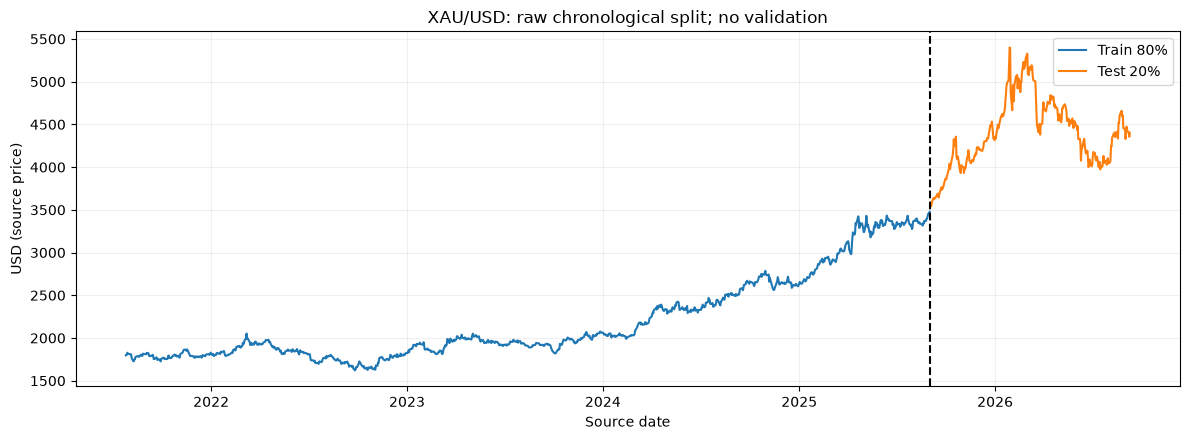

In [5]:
split_summary = pd.DataFrame([dict(partition=label, rows=b-a, start_date=df.index[a], end_date=df.index[b-1])
                             for label,a,b in [('Train',0,n_train),('Test',n_train,n)]])
save_table(split_summary, 'split_summary.csv')
display(split_summary)
fig, ax = plt.subplots()
ax.plot(df.index[:n_train], prices[:n_train], label='Train 80%')
ax.plot(df.index[n_train:], prices[n_train:], label='Test 20%')
ax.axvline(df.index[n_train], color='black', linestyle='--')
ax.set(title=f'{ASSET_NAME}: raw chronological split; no validation', ylabel=UNIT, xlabel='Source date')
ax.legend(); save_figure(fig, '01_raw_split.png')

## 6. Descriptive EDA
These full-sample plots describe the supplied data; model settings remain the previously declared ones.

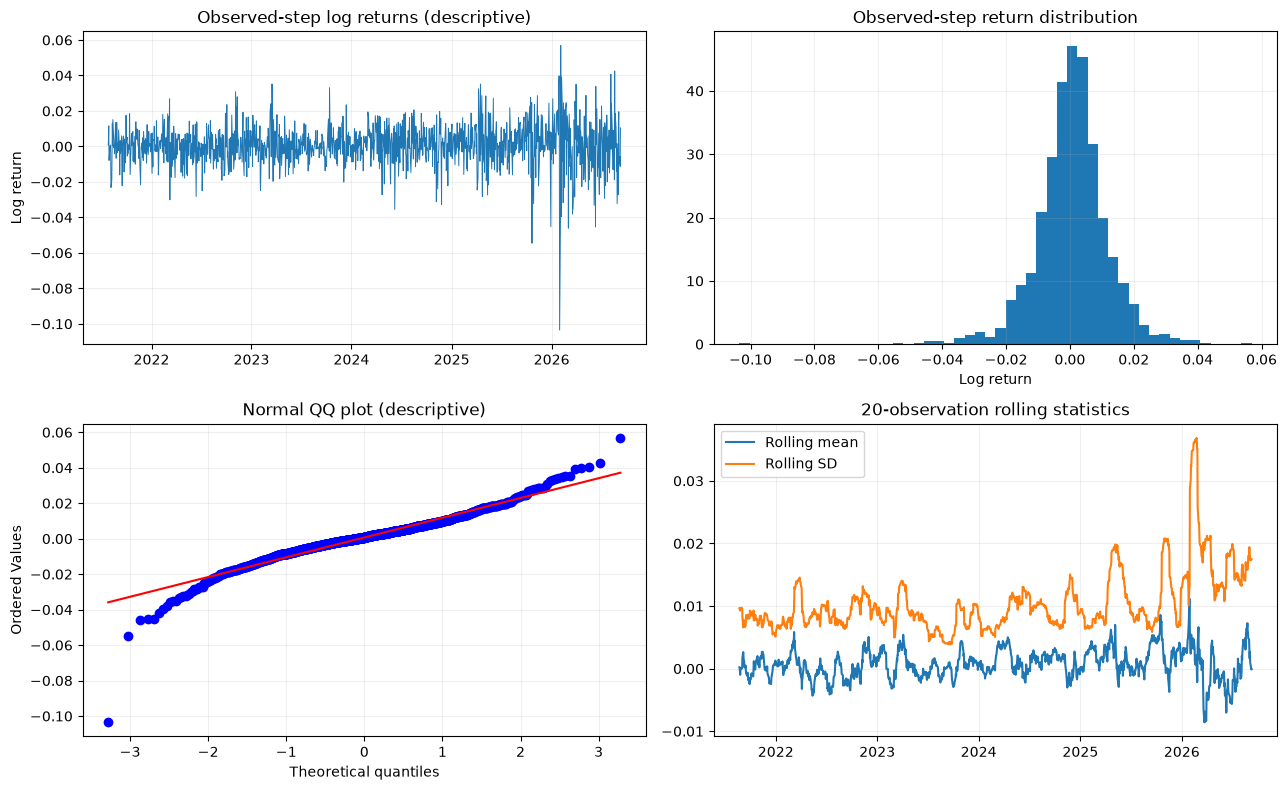

In [6]:
# Full-sample descriptive plots do not supply model settings or selection decisions.
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes[0,0].plot(df.index[1:], returns[1:], linewidth=.7)
axes[0,0].set(title='Observed-step log returns (descriptive)', ylabel='Log return')
axes[0,1].hist(returns[1:], bins=50, density=True)
axes[0,1].set(title='Observed-step return distribution', xlabel='Log return')
stats.probplot(returns[1:], dist='norm', plot=axes[1,0])
axes[1,0].set_title('Normal QQ plot (descriptive)')
rolling = pd.Series(returns, index=df.index).rolling(ROLLING_WINDOW)
axes[1,1].plot(rolling.mean(), label='Rolling mean')
axes[1,1].plot(rolling.std(), label='Rolling SD')
axes[1,1].set_title(f'{ROLLING_WINDOW}-observation rolling statistics')
axes[1,1].legend(); save_figure(fig, '02_descriptive_eda.png')

### Descriptive Statistics

Price and observed-step log return, reported separately for the full sample,
the first 80% (Train), and the final 20% (Test), using the notebook's raw
chronological split before scaling or windowing. Columns identify each sample;
rows give units, dates, Count, Mean, SD, Min, Q1, Median, Q3, Max, Skewness,
and Excess kurtosis.

SD uses `ddof=1`; skewness and excess kurtosis use pandas' bias-corrected
estimators (normal-distribution excess kurtosis = 0). Log returns are natural-log
changes, not percentages, across successive observed dates. The first full-sample
return is undefined and excluded. Returns belong to their ending date, so the
first Test return uses the last Train price. Calendar gaps are not filled.
Full-sample and Test statistics are descriptive reporting only, not inputs to
model selection or fitting. The tables below were calculated from the supplied
source data without rerunning model training.


In [ ]:
# Descriptive reporting only; this cell does not fit or configure a model.
def _make_descriptive_statistics(price, train_ratio):
    assert price.index.is_monotonic_increasing and price.index.is_unique
    assert price.notna().all() and np.isfinite(price).all() and price.gt(0).all()
    split = int(train_ratio * len(price))
    assert 0 < split < len(price)
    # Assign returns to their ending date; retain the Train-to-Test boundary return.
    log_return = np.log(price).diff()
    rows = []
    for variable, series, unit in [('Price', price, 'USD (source price)'),
                                    ('Log return', log_return, 'natural log; not percent')]:
        for sample, start, end in [('Full sample', 0, len(price)),
                                    ('Train', 0, split), ('Test', split, len(price))]:
            values = series.iloc[start:end].dropna()
            summary = values.describe(percentiles=[0.25, 0.5, 0.75])
            rows.append({'Variable': variable, 'Sample': sample, 'Unit': unit,
                'Start': str(values.index[0].date()), 'End': str(values.index[-1].date()),
                'Count': int(summary['count']), 'Mean': summary['mean'],
                'SD': summary['std'], 'Min': summary['min'], 'Q1': summary['25%'],
                'Median': summary['50%'], 'Q3': summary['75%'], 'Max': summary['max'],
                'Skewness': values.skew(), 'Excess kurtosis': values.kurt()})
    return pd.DataFrame(rows)

descriptive_statistics = _make_descriptive_statistics(df['Price'], TRAIN_RATIO)
del _make_descriptive_statistics
for _descriptive_variable in ['Price', 'Log return']:
    print(_descriptive_variable)
    display(descriptive_statistics.loc[
        descriptive_statistics['Variable'].eq(_descriptive_variable)
    ].drop(columns='Variable').set_index('Sample').T)
del _descriptive_variable


Price


Sample,Full sample,Train,Test
Unit,USD (source price),USD (source price),USD (source price)
Start,2021-07-26,2021-07-26,2025-09-02
End,2026-09-09,2025-09-01,2026-09-09
Count,1333,1066,267
Mean,2635.821335,2195.377899,4394.29588
SD,1004.534442,501.830197,404.321053
Min,1621.57,1621.57,3533.73
Q1,1854.97,1822.4825,4085.46
Median,2052.41,1968.94,4356.5
Q3,3323.07,2493.8325,4668.645


Log return


Sample,Full sample,Train,Test
Unit,natural log; not percent,natural log; not percent,natural log; not percent
Start,2021-07-27,2021-07-27,2025-09-02
End,2026-09-09,2025-09-01,2026-09-09
Count,1332,1065,267
Mean,0.000672,0.000619,0.000884
SD,0.011463,0.009301,0.017648
Min,-0.103497,-0.03552,-0.103497
Q1,-0.004949,-0.004591,-0.007284
Median,0.000764,0.000586,0.002484
Q3,0.006912,0.005805,0.010461


## 7. Train-only scaling and chronological MIMO windows
All H intermediate training targets precede Test. Complete stateless Train windows may be shuffled during optimization; the dates inside each window stay chronological.

In [7]:
scaler = StandardScaler().fit(returns[1:n_train, None])
check('Scaler fitted on Train only', int(scaler.n_samples_seen_) == n_train - 1,
      f'Fit dates {df.index[1].date()} through {df.index[T].date()}; first undefined return excluded.')
np.testing.assert_allclose(scaler.mean_[0], returns[1:n_train].mean(), atol=1e-12)
np.testing.assert_allclose(scaler.scale_[0], returns[1:n_train].std(ddof=0), atol=1e-12)
z = np.full(n, np.nan)
z[1:] = scaler.transform(returns[1:,None]).ravel()
scaler_hash = joblib.hash(scaler)
joblib.dump(scaler, MODEL_DIR / 'input_scaler.joblib')
write_json(MODEL_DIR / 'scaler_provenance.json', dict(first_index=1, last_index=T,
    first_date=df.index[1], last_date=df.index[T], n_samples=n_train-1,
    mean=float(scaler.mean_[0]), scale=float(scaler.scale_[0]), ddof=0, sha256=scaler_hash))

In [8]:
train_origins = np.arange(LOOKBACK, n_train-MAX_H)
input_idx = train_origins[:,None] - np.arange(LOOKBACK-1, -1, -1)[None,:]
target_idx = train_origins[:,None] + np.arange(1,MAX_H+1)[None,:]
check('All MIMO Train targets precede Test', target_idx.max() == T and input_idx.min() == 1,
      'Inputs oldest to newest; all intermediate target dates stay inside Train.')
check('MIMO training count', len(train_origins) == n_train-LOOKBACK-MAX_H)
X_train = z[input_idx][...,None].astype(np.float32)
y_train = z[target_idx].astype(np.float32)
check('Finite scaled training windows', np.isfinite(X_train).all() and np.isfinite(y_train).all())
window_audit = pd.DataFrame(dict(origin_index=train_origins, origin_date=df.index[train_origins],
    input_start_date=df.index[input_idx[:,0]], input_end_date=df.index[input_idx[:,-1]],
    target_start_date=df.index[target_idx[:,0]], target_end_date=df.index[target_idx[:,-1]]))
save_table(window_audit, 'training_window_audit.csv')
display(window_audit.iloc[[0,-1]])
print('Train shapes:', X_train.shape, y_train.shape)

,origin_index,origin_date,input_start_date,input_end_date,target_start_date,target_end_date
0,40,2021-09-20,2021-07-27,2021-09-20,2021-09-21,2021-11-01
995,1035,2025-07-21,2025-05-27,2025-07-21,2025-07-22,2025-09-01


Train shapes: (996, 40, 1) (996, 30)


## 8. Architecture and fixed-budget training
Five predefined seeds, each trained once; all final-budget models are retained equally. No callbacks or validation-based model selection. Loss reduction and parameter/sample ratios are descriptive, not acceptance gates. PatchTST uses learned positions, residual attention, GELU, post-residual BatchNorm, non-affine RevIN and feature-major flattening; all buffers freeze at inference.

In [9]:
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
assert D_MODEL % N_HEADS == 0 and LOOKBACK + STRIDE >= PATCH_LEN
patch_count=(LOOKBACK+STRIDE-PATCH_LEN)//STRIDE+1
check('Patch geometry',patch_count>0,statistic=patch_count)
class PatchEncoderBlock(nn.Module):
    def __init__(self):
        super().__init__()
        self.heads = N_HEADS
        self.head_dim = D_MODEL//N_HEADS
        self.qkv = nn.Linear(D_MODEL,3*D_MODEL)
        self.project = nn.Sequential(nn.Linear(D_MODEL,D_MODEL),nn.Dropout(DROPOUT))
        self.attention_residual = nn.Dropout(DROPOUT)
        self.bn_attention = nn.BatchNorm1d(D_MODEL)
        self.ff = nn.Sequential(nn.Linear(D_MODEL,D_FF),nn.GELU(),
            nn.Dropout(DROPOUT),nn.Linear(D_FF,D_MODEL))
        self.ff_residual = nn.Dropout(DROPOUT)
        self.bn_ff = nn.BatchNorm1d(D_MODEL)

    def forward(self,x,previous_scores=None):
        batch,patches,_ = x.shape
        q,k,v = self.qkv(x).chunk(3,dim=-1)
        def heads(t): return t.reshape(batch,patches,self.heads,self.head_dim).transpose(1,2)
        q,k,v = heads(q),heads(k),heads(v)
        scores = (q@k.transpose(-1,-2)) * (self.head_dim**-0.5)
        if previous_scores is not None: scores = scores+previous_scores
        attended = (scores.softmax(dim=-1)@v).transpose(1,2).reshape(batch,patches,D_MODEL)
        x = self.bn_attention((x+self.attention_residual(self.project(attended))).transpose(1,2)).transpose(1,2)
        x = self.bn_ff((x+self.ff_residual(self.ff(x))).transpose(1,2)).transpose(1,2)
        return x,scores

class PatchTST(nn.Module):
    def __init__(self):
        super().__init__()
        assert D_MODEL%N_HEADS==0 and PADDING_PATCH=='end'
        self.patch_count = (LOOKBACK+STRIDE-PATCH_LEN)//STRIDE+1
        self.pad = nn.ReplicationPad1d((0,STRIDE))
        self.embedding = nn.Linear(PATCH_LEN,D_MODEL)
        self.position = nn.Parameter(torch.empty(self.patch_count,D_MODEL))
        nn.init.uniform_(self.position,-0.02,0.02)
        self.embedding_dropout = nn.Dropout(DROPOUT)
        self.encoder = nn.ModuleList([PatchEncoderBlock() for _ in range(N_LAYERS)])
        self.head = nn.Sequential(nn.Flatten(start_dim=1),nn.Dropout(HEAD_DROPOUT),
            nn.Linear(self.patch_count*D_MODEL,MAX_H))

    def forward(self,x):
        assert x.ndim==3 and x.shape[1:]==(LOOKBACK,1)
        mean = x.mean(dim=1,keepdim=True).detach()
        std = torch.sqrt(x.var(dim=1,keepdim=True,unbiased=False)+1e-5).detach()
        normalized = (x-mean)/std if REVIN else x
        patches = self.pad(normalized.transpose(1,2)).unfold(-1,PATCH_LEN,STRIDE).squeeze(1)
        assert patches.shape[1:]==(self.patch_count,PATCH_LEN)
        encoded = self.embedding_dropout(self.embedding(patches)+self.position)
        scores = None
        for block in self.encoder: encoded,scores = block(encoded,scores)
        # Official flattened representation is feature-major: (D_MODEL, patches).
        predicted = self.head(encoded.transpose(1,2))
        if REVIN: predicted = predicted*std[:,0,:]+mean[:,0,:]
        return predicted

def weights_digest(model):
    digest=hashlib.sha256()
    for name,value in sorted(model.state_dict().items()):
        array=value.detach().cpu().contiguous().numpy()
        digest.update(name.encode()); digest.update(str(array.dtype).encode())
        digest.update(str(array.shape).encode()); digest.update(array.tobytes())
    return digest.hexdigest()

set_seed(SEEDS[0])
architecture_model=PatchTST().to(DEVICE)
parameter_count=sum(p.numel() for p in architecture_model.parameters())
architecture_model.eval()
with torch.no_grad():
    output_probe=architecture_model(torch.from_numpy(X_train[:2]).to(DEVICE))
assert output_probe.shape==(2,MAX_H) and torch.isfinite(output_probe).all()
architecture_text=str(architecture_model)+f'\nTotal trainable parameters: {parameter_count}\nTraining samples: {len(X_train)}\n'
print(architecture_text)
(MODEL_DIR/'model_architecture.txt').write_text(architecture_text,encoding='utf-8')
del architecture_model

PatchTST(
  (pad): ReplicationPad1d((0, 8))
  (embedding): Linear(in_features=16, out_features=16, bias=True)
  (embedding_dropout): Dropout(p=0.3, inplace=False)
  (encoder): ModuleList(
    (0-2): 3 x PatchEncoderBlock(
      (qkv): Linear(in_features=16, out_features=48, bias=True)
      (project): Sequential(
        (0): Linear(in_features=16, out_features=16, bias=True)
        (1): Dropout(p=0.3, inplace=False)
      )
      (attention_residual): Dropout(p=0.3, inplace=False)
      (bn_attention): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (ff): Sequential(
        (0): Linear(in_features=16, out_features=128, bias=True)
        (1): GELU(approximate='none')
        (2): Dropout(p=0.3, inplace=False)
        (3): Linear(in_features=128, out_features=16, bias=True)
      )
      (ff_residual): Dropout(p=0.3, inplace=False)
      (bn_ff): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)

In [10]:
models, frozen_weight_hashes, training_rows, training_audit_rows, lr_rows = {}, {}, [], [], []
train_dataset = TensorDataset(torch.from_numpy(X_train),torch.from_numpy(y_train))
for seed in SEEDS:
    set_seed(seed)
    generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(train_dataset,batch_size=BATCH_SIZE,shuffle=True,
        generator=generator,num_workers=0,drop_last=False)
    model = PatchTST().to(DEVICE)
    optimizer = Adam(model.parameters(),lr=LR)
    scheduler = OneCycleLR(optimizer,max_lr=LR,pct_start=PCT_START,
        epochs=EPOCHS,steps_per_epoch=len(train_loader))
    loss_fn = nn.MSELoss()
    epoch_losses=[]
    started=time.perf_counter()
    print(f'Training seed={seed}: {EPOCHS} fixed epochs',flush=True)
    for epoch in range(1,EPOCHS+1):
        model.train()
        total_loss=0.0
        total_samples=0
        for inputs,targets in train_loader:
            inputs,targets=inputs.to(DEVICE),targets.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            predicted=model(inputs)
            loss=loss_fn(predicted,targets)
            assert torch.isfinite(loss), f'Non-finite Train loss: seed={seed}, epoch={epoch}'
            loss.backward()
            lr_rows.append(dict(seed=seed,step=len(lr_rows)+1,learning_rate=optimizer.param_groups[0]['lr']))
            optimizer.step()
            scheduler.step()
            total_loss+=loss.item()*len(inputs)
            total_samples+=len(inputs)
        epoch_loss=total_loss/total_samples
        epoch_losses.append(epoch_loss)
        training_rows.append(dict(seed=seed,epoch=epoch,loss=epoch_loss))
        if epoch%20==0: print(f'  seed={seed} epoch={epoch}: Train MSE={epoch_loss:.6f}',flush=True)
    model.eval()
    models[seed]=model
    frozen_weight_hashes[seed]=weights_digest(model)
    torch.save(model.state_dict(),MODEL_DIR/f'patchtst_seed{seed}.pt')
    training_audit_rows.append(dict(seed=seed,n_epochs=len(epoch_losses),
        first_loss=epoch_losses[0],final_loss=epoch_losses[-1],
        loss_reduced=epoch_losses[-1]<epoch_losses[0],seconds=time.perf_counter()-started))
    print(f'Saved seed={seed}; Train MSE {epoch_losses[0]:.6f} -> {epoch_losses[-1]:.6f}',flush=True)

save_table(pd.DataFrame(lr_rows),'learning_rate_schedule.csv')
for row in training_audit_rows:
    row['status']='REPORTED'
check('All PatchTST seeds complete fixed budget',len(training_rows)==len(SEEDS)*EPOCHS and np.isfinite([r['loss'] for r in training_rows]).all())
def daily_predictions(inputs):
    outputs={}
    for seed,model in models.items():
        model.eval()
        with torch.no_grad():
            pred=model(torch.from_numpy(inputs).to(DEVICE)).cpu().numpy()
        outputs[seed]=scaler.inverse_transform(pred.reshape(-1,1)).reshape(len(inputs),MAX_H)
    return outputs

Training seed=0: 100 fixed epochs


  seed=0 epoch=20: Train MSE=1.297826


  seed=0 epoch=40: Train MSE=1.199607


  seed=0 epoch=60: Train MSE=1.140264


  seed=0 epoch=80: Train MSE=1.118174


...

  seed=4 epoch=40: Train MSE=1.187709


  seed=4 epoch=60: Train MSE=1.124753


  seed=4 epoch=80: Train MSE=1.108069


  seed=4 epoch=100: Train MSE=1.104139


Saved seed=4; Train MSE 1.348097 -> 1.104139


,seed,n_epochs,first_loss,final_loss,loss_reduced,seconds,status
0,0,100,1.356038,1.120983,True,21.234147,REPORTED
1,1,100,1.372264,1.090452,True,27.843810,REPORTED
2,2,100,1.399183,1.111841,True,28.754463,REPORTED
3,3,100,1.370617,1.115511,True,27.910836,REPORTED
4,4,100,1.348097,1.104139,True,27.796749,REPORTED


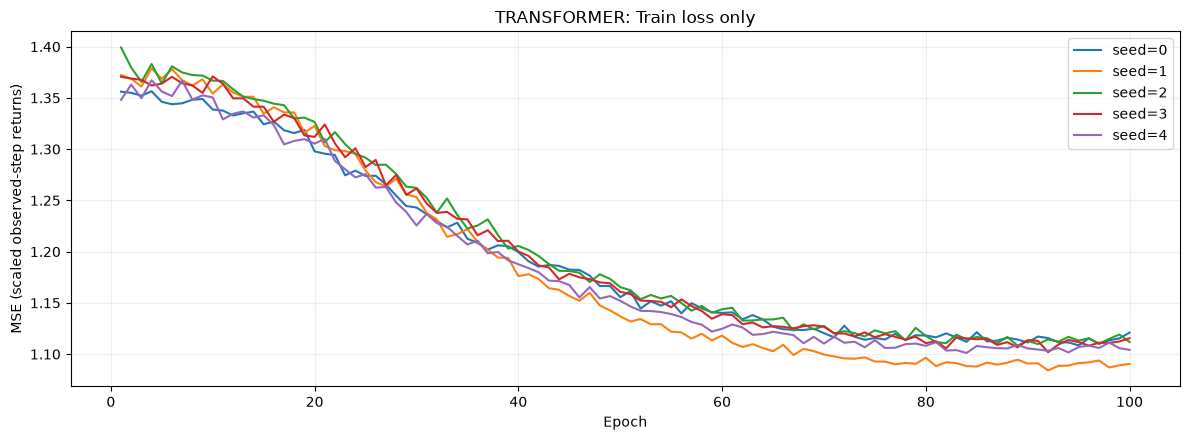

C:\Users\User\anaconda3\envs\vs_nine_tf\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,sample,check,statistic,p_value,status,interpretation
0,"Train first-output log-return errors, equal-se...",Ljung-Box lag 10,4.277893,9.339412e-01,REPORTED,No rejection of residual independence; model_d...
1,"Train first-output log-return errors, equal-se...",Ljung-Box lag 20,14.481131,8.052882e-01,REPORTED,No rejection of residual independence; model_d...
2,"Train first-output log-return errors, equal-se...",Ljung-Box lag 30,23.916394,7.757940e-01,REPORTED,No rejection of residual independence; model_d...
3,"Train first-output log-return errors, equal-se...",Residual mean t-test,-1.012666,3.114658e-01,REPORTED,"Mean=-0.00030199132; descriptive, dependent er..."
4,"Train first-output log-return errors, equal-se...",ARCH LM,70.653817,3.314864e-11,REPORTED,Conditional variance evidence; no retuning
5,"Train first-output log-return errors, equal-se...",Jarque-Bera,68.967608,1.056511e-15,REPORTED,Normality diagnostic; skew=-0.068186; kurtosis...


,parameters_per_seed,training_windows,parameter_to_window_ratio,seed_count,status,interpretation
0,18958,996,19.034137,5,REPORTED,Descriptive ratio; no universal pass threshold...


In [11]:
training_loss=pd.DataFrame(training_rows)
training_audit=pd.DataFrame(training_audit_rows)
save_table(training_loss,'training_loss.csv'); save_table(training_audit,'training_audit.csv')
display(training_audit)
fig,ax=plt.subplots()
for seed in SEEDS:
    g=training_loss.loc[training_loss.seed.eq(seed)]
    ax.plot(g.epoch,g.loss,label=f'seed={seed}')
ax.set(title=f'{MODEL}: Train loss only',xlabel='Epoch',ylabel='MSE (scaled observed-step returns)')
ax.legend(); save_figure(fig,'03_training_loss.png')
def model_fingerprint():
    return {'models':{seed:weights_digest(model) for seed,model in models.items()},'scaler':joblib.hash(scaler)}
frozen_state=model_fingerprint()
train_pred=daily_predictions(X_train)
train_mean=np.mean(np.stack(list(train_pred.values())),axis=0)
train_error=returns[train_origins+1]-train_mean[:,0]
train_diagnostics=residual_report(train_error,'Train first-output log-return errors, equal-seed ensemble')
save_table(train_diagnostics,'train_residual_diagnostics.csv'); display(train_diagnostics)
complexity=pd.DataFrame([dict(parameters_per_seed=parameter_count,training_windows=len(X_train),
    parameter_to_window_ratio=parameter_count/len(X_train),seed_count=len(SEEDS),status='REPORTED',
    interpretation='Descriptive ratio; no universal pass threshold and no separate validation estimate')])
save_table(complexity,'model_complexity.csv'); display(complexity)
check('Frozen inference on Train',model_fingerprint()==frozen_state)
def predict_cumulative(origins, horizons=None):
    horizons = HORIZONS if horizons is None else horizons
    origins=np.asarray(origins)
    idx=origins[:,None]-np.arange(LOOKBACK-1,-1,-1)[None,:]
    assert idx.min()>=1 and (idx<=origins[:,None]).all()
    inputs=z[idx][...,None].astype(np.float32)
    per_seed=daily_predictions(inputs)
    mean_daily=np.mean(np.stack(list(per_seed.values())),axis=0)
    # Average returns first, then accumulate/compound; no intervening actuals enter the forecast path.
    cumulative=np.cumsum(mean_daily,axis=1)
    output={h:cumulative[:,h-1] for h in horizons}
    seed_output={seed:{h:np.cumsum(pred,axis=1)[:,h-1] for h in horizons} for seed,pred in per_seed.items()}
    return output,seed_output

## 9. Rolling-origin Test forecast calculation
Origins start at the last Train row. At each origin, prior observed Test history may update inputs/filtering states. It never changes fitted coefficients, weights, scalers or tree structure. A horizon-h forecast does not use actuals between its origin and target. Targets are actual source dates at row origin+h.

In [12]:
test_origins=np.arange(T,n-1)
cumulative, seed_cumulative = predict_cumulative(test_origins)
def assemble_forecasts(predictions):
    rows=[]
    for h in HORIZONS:
        valid=test_origins+h<n
        origins=test_origins[valid]
        pred=np.asarray(predictions[h])[valid]
        rows.append(pd.DataFrame(dict(h=h,origin_index=origins,target_index=origins+h,
            origin_date=df.index[origins],target_date=df.index[origins+h],price_origin=prices[origins],
            actual=prices[origins+h],forecast=prices[origins]*np.exp(pred),predicted_log_return=pred)))
    return pd.concat(rows,ignore_index=True)
forecasts=assemble_forecasts(cumulative)
seed_forecasts={seed:assemble_forecasts(pred) for seed,pred in seed_cumulative.items()}

## 10. Historical Test forecast tables
All rows appear in scrollable tables and are exported separately by horizon. ARIMA supplies model-based 95% intervals; log point forecasts are conditional medians. Other models have no calibrated intervals.

In [13]:
save_table(forecasts,'test_forecasts_all.csv')
for h in HORIZONS:
    group=forecasts.loc[forecasts.h.eq(h)].copy()
    save_table(group,f'forecasts_h{h}.csv')
    display(Markdown(f'### Historical Test forecasts: h={h} observations ({UNIT})'))
    show_table(group.drop(columns=['origin_index','target_index','predicted_log_return']))

### Historical Test forecasts: h=1 observations (USD (source price))

h,origin_date,target_date,price_origin,actual,forecast
1,2025-09-01,2025-09-02,"3,476.470000","3,533.730000","3,479.006711"
1,2025-09-02,2025-09-03,"3,533.730000","3,559.430000","3,534.617160"
1,2025-09-03,2025-09-04,"3,559.430000","3,546.170000","3,560.940569"
1,2025-09-04,2025-09-05,"3,546.170000","3,586.810000","3,553.107104"
1,2025-09-05,2025-09-08,"3,586.810000","3,635.840000","3,594.789090"
1,2025-09-08,2025-09-09,"3,635.840000","3,626.480000","3,640.101443"
1,2025-09-09,2025-09-10,"3,626.480000","3,640.740000","3,633.747997"
1,2025-09-10,2025-09-11,"3,640.740000","3,634.090000","3,651.733474"
1,2025-09-11,2025-09-12,"3,634.090000","3,643.130000","3,639.613954"
1,2025-09-12,2025-09-15,"3,643.130000","3,679.130000","3,652.225439"


### Historical Test forecasts: h=3 observations (USD (source price))

h,origin_date,target_date,price_origin,actual,forecast
3,2025-09-01,2025-09-04,"3,476.470000","3,546.170000","3,486.410873"
3,2025-09-02,2025-09-05,"3,533.730000","3,586.810000","3,540.927958"
3,2025-09-03,2025-09-08,"3,559.430000","3,635.840000","3,571.035922"
3,2025-09-04,2025-09-09,"3,546.170000","3,626.480000","3,566.050025"
3,2025-09-05,2025-09-10,"3,586.810000","3,640.740000","3,603.797796"
3,2025-09-08,2025-09-11,"3,635.840000","3,634.090000","3,657.124246"
3,2025-09-09,2025-09-12,"3,626.480000","3,643.130000","3,649.197896"
3,2025-09-10,2025-09-15,"3,640.740000","3,679.130000","3,660.901936"
3,2025-09-11,2025-09-16,"3,634.090000","3,689.800000","3,656.408921"
3,2025-09-12,2025-09-17,"3,643.130000","3,660.040000","3,665.643415"


### Historical Test forecasts: h=5 observations (USD (source price))

...

h,origin_date,target_date,price_origin,actual,forecast
14,2025-09-01,2025-09-19,"3,476.470000","3,684.980000","3,529.831273"
14,2025-09-02,2025-09-22,"3,533.730000","3,746.470000","3,611.421772"
14,2025-09-03,2025-09-23,"3,559.430000","3,764.190000","3,634.546860"
14,2025-09-04,2025-09-24,"3,546.170000","3,736.290000","3,605.271086"
14,2025-09-05,2025-09-25,"3,586.810000","3,749.370000","3,661.006861"
14,2025-09-08,2025-09-26,"3,635.840000","3,760.240000","3,706.867670"
14,2025-09-09,2025-09-29,"3,626.480000","3,833.930000","3,718.669265"
14,2025-09-10,2025-09-30,"3,640.740000","3,858.510000","3,734.392854"
14,2025-09-11,2025-10-01,"3,634.090000","3,865.800000","3,728.491946"
14,2025-09-12,2025-10-02,"3,643.130000","3,856.530000","3,738.585422"


### Historical Test forecasts: h=21 observations (USD (source price))

h,origin_date,target_date,price_origin,actual,forecast
21,2025-09-01,2025-09-30,"3,476.470000","3,858.510000","3,553.629773"
21,2025-09-02,2025-10-01,"3,533.730000","3,865.800000","3,638.082903"
21,2025-09-03,2025-10-02,"3,559.430000","3,856.530000","3,672.535972"
21,2025-09-04,2025-10-03,"3,546.170000","3,886.830000","3,644.580499"
21,2025-09-05,2025-10-06,"3,586.810000","3,961.090000","3,696.892885"
21,2025-09-08,2025-10-07,"3,635.840000","3,983.820000","3,762.187552"
21,2025-09-09,2025-10-08,"3,626.480000","4,038.900000","3,776.709923"
21,2025-09-10,2025-10-09,"3,640.740000","3,976.290000","3,795.739738"
21,2025-09-11,2025-10-10,"3,634.090000","4,018.300000","3,802.302208"
21,2025-09-12,2025-10-13,"3,643.130000","4,110.700000","3,801.668933"


### Historical Test forecasts: h=30 observations (USD (source price))

h,origin_date,target_date,price_origin,actual,forecast
30,2025-09-01,2025-10-13,"3,476.470000","4,110.700000","3,591.763736"
30,2025-09-02,2025-10-14,"3,533.730000","4,142.310000","3,700.671054"
30,2025-09-03,2025-10-15,"3,559.430000","4,208.580000","3,738.689133"
30,2025-09-04,2025-10-16,"3,546.170000","4,326.180000","3,703.309577"
30,2025-09-05,2025-10-17,"3,586.810000","4,249.980000","3,754.712535"
30,2025-09-08,2025-10-20,"3,635.840000","4,356.500000","3,845.752066"
30,2025-09-09,2025-10-21,"3,626.480000","4,125.100000","3,839.260440"
30,2025-09-10,2025-10-22,"3,640.740000","4,094.070000","3,865.312413"
30,2025-09-11,2025-10-23,"3,634.090000","4,126.170000","3,863.195229"
30,2025-09-12,2025-10-24,"3,643.130000","4,112.100000","3,855.799889"


## 11. Future forecasts from the latest observed origin
Same original Train parameters; no all-data refit. One row per horizon. Future dates are conditional weekday-pattern projections, explicitly distinct from observed historical target dates. No actual values or evaluation metrics exist for these rows.

In [14]:
# These are projected source-calendar dates, not verified exchange/holiday sessions.
future_dates=pd.date_range(df.index[-1]+calendar_offset,periods=MAX_H,freq=calendar_offset)
future_rows=[]
if MODEL=='ARIMA':
    latest_state=res.apply(log_price,refit=False)
    np.testing.assert_array_equal(latest_state.params,frozen_params)
    fc=latest_state.get_forecast(steps=MAX_H)
    means=np.asarray(fc.predicted_mean); intervals=np.asarray(fc.conf_int(alpha=ALPHA))
    for h in HORIZONS:
        future_rows.append(dict(h=h,origin_date=df.index[-1],target_date=future_dates[h-1],
            target_date_status='PROJECTED: weekday pattern, holidays/omissions unknown',price_origin=prices[-1],
            forecast=np.exp(means[h-1]),lower95=np.exp(intervals[h-1,0]),upper95=np.exp(intervals[h-1,1])))
else:
    latest,_=predict_cumulative(np.array([n-1]))
    for h in HORIZONS:
        future_rows.append(dict(h=h,origin_date=df.index[-1],target_date=future_dates[h-1],
            target_date_status='PROJECTED: weekday pattern, holidays/omissions unknown',price_origin=prices[-1],
            forecast=prices[-1]*np.exp(latest[h][0])))
future_forecasts=pd.DataFrame(future_rows)
save_table(future_forecasts,'future_forecasts.csv')
display(Markdown('### Future forecasts: common latest origin; original Train fit'))
show_table(future_forecasts)
print('Future values have no actuals or metrics. Forecasts count future observations; displayed dates are conditional projections.')
check('Fitted model and preprocessing remain frozen', model_fingerprint()==frozen_state,
      'Includes SVR scalers, XGBoost trees, LSTM weights or full PatchTST state including BatchNorm buffers.')
if MODEL in ['SVR','LSTM','TRANSFORMER']:
    check('Input scaler remains frozen',joblib.hash(scaler)==scaler_hash)
write_json(MODEL_DIR/'frozen_state_audit.json',dict(before=frozen_state,after=model_fingerprint(),
    original_fit_end_date=df.index[T],latest_observed_input_date=df.index[-1],refit=False))

### Future forecasts: common latest origin; original Train fit

h,origin_date,target_date,target_date_status,price_origin,forecast
1,2026-09-09,2026-09-10,"PROJECTED: weekday pattern, holidays/omissions unknown","4,401.550000","4,424.169536"
3,2026-09-09,2026-09-14,"PROJECTED: weekday pattern, holidays/omissions unknown","4,401.550000","4,448.821257"
5,2026-09-09,2026-09-16,"PROJECTED: weekday pattern, holidays/omissions unknown","4,401.550000","4,461.767844"
7,2026-09-09,2026-09-18,"PROJECTED: weekday pattern, holidays/omissions unknown","4,401.550000","4,481.542426"
14,2026-09-09,2026-09-29,"PROJECTED: weekday pattern, holidays/omissions unknown","4,401.550000","4,532.659250"
21,2026-09-09,2026-10-08,"PROJECTED: weekday pattern, holidays/omissions unknown","4,401.550000","4,574.281001"
30,2026-09-09,2026-10-21,"PROJECTED: weekday pattern, holidays/omissions unknown","4,401.550000","4,695.219881"


Future values have no actuals or metrics. Forecasts count future observations; displayed dates are conditional projections.


### 11.1 Daily future forecast tables - next 7 and 30 steps

Horizons count future observations. Dates retain the declared source-weekday pattern, including Sunday for WTI; they are conditional projections with holidays and source omissions unknown. These are not 7/30 elapsed calendar days.

Uses the existing fixed Train MIMO path, with ensemble and per-seed forecasts. Seed spread is not a calibrated prediction interval.

Exports `tables/future_forecast_daily_7d.csv` and `tables/future_forecast_daily_30d.csv` under the existing model output directory.


In [15]:
daily_steps = max(DAILY_FORECAST_WINDOWS)
daily_origin = pd.Timestamp(df.index[-1])
daily_origin_price = float(df['Price'].iloc[-1])
daily_dates = pd.DatetimeIndex(future_dates[:daily_steps])
assert len(daily_dates) == daily_steps
assert daily_dates.is_unique and daily_dates.is_monotonic_increasing
assert (daily_dates > daily_origin).all()
future_forecast_daily = pd.DataFrame(dict(origin_date=daily_origin,
    h=np.arange(1, daily_steps + 1), target_date=daily_dates,
    day_of_week=daily_dates.day_name(), price_origin=daily_origin_price))
future_forecast_daily['target_date_status'] = 'PROJECTED: weekday pattern, holidays/omissions unknown'
# Request the existing full MIMO output path with fixed weights/scaler.
daily_horizons = list(range(1, daily_steps + 1))
daily_cumulative, daily_seed_cumulative = predict_cumulative(np.array([n-1]), horizons=daily_horizons)
future_forecast_daily['forecast'] = [np.float64(daily_origin_price)*np.exp(daily_cumulative[h][0]) for h in daily_horizons]
for seed in SEEDS:
    future_forecast_daily[f'forecast_seed{seed}'] = [
        np.float64(daily_origin_price)*np.exp(daily_seed_cumulative[seed][h][0]) for h in daily_horizons]
assert model_fingerprint() == frozen_state
assert joblib.hash(scaler) == scaler_hash
daily_forecast_columns = ['forecast', *[f'forecast_seed{seed}' for seed in SEEDS]]
assert len(future_forecast_daily) == daily_steps
assert future_forecast_daily['origin_date'].nunique() == 1
assert future_forecast_daily['h'].tolist() == list(range(1, daily_steps + 1))
assert future_forecast_daily['target_date'].equals(pd.Series(daily_dates, name='target_date'))
values = future_forecast_daily[daily_forecast_columns].to_numpy()
assert np.isfinite(values).all() and (values > 0).all()
np.testing.assert_allclose(future_forecast_daily.set_index('h').loc[HORIZONS, ['forecast']],
    future_forecasts.set_index('h').loc[HORIZONS, ['forecast']], rtol=1e-12)
assert (future_forecast_daily.set_index('h').loc[HORIZONS, 'target_date'].to_numpy() ==
        future_forecasts.set_index('h').loc[HORIZONS, 'target_date'].to_numpy()).all()
future_daily_tables = {}
for days in DAILY_FORECAST_WINDOWS:
    table = future_forecast_daily.iloc[:days].copy()
    assert len(table) == days and table['h'].tolist() == list(range(1, days + 1))
    future_daily_tables[days] = table
    save_table(table, f'future_forecast_daily_{days}d.csv')
    display(Markdown(f'**Next {days} projected observations - origin {daily_origin.date()}, last observed price {daily_origin_price:,.6f} {UNIT}**'))
    shown = table.copy()
    for column in ['origin_date', 'target_date']:
        shown[column] = shown[column].dt.strftime('%Y-%m-%d')
    display(HTML(shown.to_html(index=False, float_format=lambda value: f'{value:,.6f}')))
assert all((TABLE_DIR/f'future_forecast_daily_{days}d.csv').is_file() for days in DAILY_FORECAST_WINDOWS)


**Next 7 projected observations - origin 2026-09-09, last observed price 4,401.550000 USD (source price)**

origin_date,h,target_date,day_of_week,price_origin,target_date_status,forecast,forecast_seed0,forecast_seed1,forecast_seed2,forecast_seed3,forecast_seed4
2026-09-09,1,2026-09-10,Thursday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,424.169536","4,424.955545","4,418.521079","4,414.672364","4,438.163960","4,424.570936"
2026-09-09,2,2026-09-11,Friday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,436.641264","4,446.853610","4,430.766135","4,420.689163","4,438.409522","4,446.542460"
2026-09-09,3,2026-09-14,Monday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,448.821257","4,441.115954","4,448.104509","4,449.602543","4,455.176491","4,450.119378"
2026-09-09,4,2026-09-15,Tuesday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,455.140811","4,449.241546","4,436.032606","4,466.904187","4,464.297974","4,459.299104"
2026-09-09,5,2026-09-16,Wednesday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,461.767844","4,449.477139","4,443.749976","4,471.591908","4,462.607897","4,481.519338"
2026-09-09,6,2026-09-17,Thursday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,481.528783","4,456.892279","4,463.575979","4,494.904055","4,473.204328","4,519.359011"
2026-09-09,7,2026-09-18,Friday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,481.542426","4,460.585157","4,456.439983","4,503.202275","4,459.673219","4,528.278482"


**Next 30 projected observations - origin 2026-09-09, last observed price 4,401.550000 USD (source price)**

origin_date,h,target_date,day_of_week,price_origin,target_date_status,forecast,forecast_seed0,forecast_seed1,forecast_seed2,forecast_seed3,forecast_seed4
2026-09-09,1,2026-09-10,Thursday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,424.169536","4,424.955545","4,418.521079","4,414.672364","4,438.163960","4,424.570936"
2026-09-09,2,2026-09-11,Friday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,436.641264","4,446.853610","4,430.766135","4,420.689163","4,438.409522","4,446.542460"
2026-09-09,3,2026-09-14,Monday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,448.821257","4,441.115954","4,448.104509","4,449.602543","4,455.176491","4,450.119378"
2026-09-09,4,2026-09-15,Tuesday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,455.140811","4,449.241546","4,436.032606","4,466.904187","4,464.297974","4,459.299104"
2026-09-09,5,2026-09-16,Wednesday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,461.767844","4,449.477139","4,443.749976","4,471.591908","4,462.607897","4,481.519338"
2026-09-09,6,2026-09-17,Thursday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,481.528783","4,456.892279","4,463.575979","4,494.904055","4,473.204328","4,519.359011"
2026-09-09,7,2026-09-18,Friday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,481.542426","4,460.585157","4,456.439983","4,503.202275","4,459.673219","4,528.278482"
2026-09-09,8,2026-09-21,Monday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,484.155984","4,449.461922","4,475.578621","4,520.462992","4,451.513521","4,524.349486"
2026-09-09,9,2026-09-22,Tuesday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,488.877286","4,452.359871","4,494.317434","4,528.048137","4,455.257821","4,514.928397"
2026-09-09,10,2026-09-23,Wednesday,"4,401.550000","PROJECTED: weekday pattern, holidays/omissions unknown","4,496.215819","4,476.082863","4,486.055419","4,532.377483","4,470.034581","4,516.854066"


### 11.2 Future forecast plots from the latest observed date

These 7- and 30-step plots reuse the future forecast tables above and the original Train-fitted model. The dashed line marks the last observed date; every forecast target lies after it. The left panel provides recent price history and the right panel enlarges the future path.

**Step unit:** projected observations. Weekday-based dates; holidays and source omissions are unknown.

**Uncertainty:** Seed range is not a calibrated prediction interval.

**Rendering note:** Added outputs were rendered from saved forecasts without retraining. On Run All, this cell uses the freshly computed in-memory forecast table. The forecast origin is the dataset end date, not the current wall-clock date.

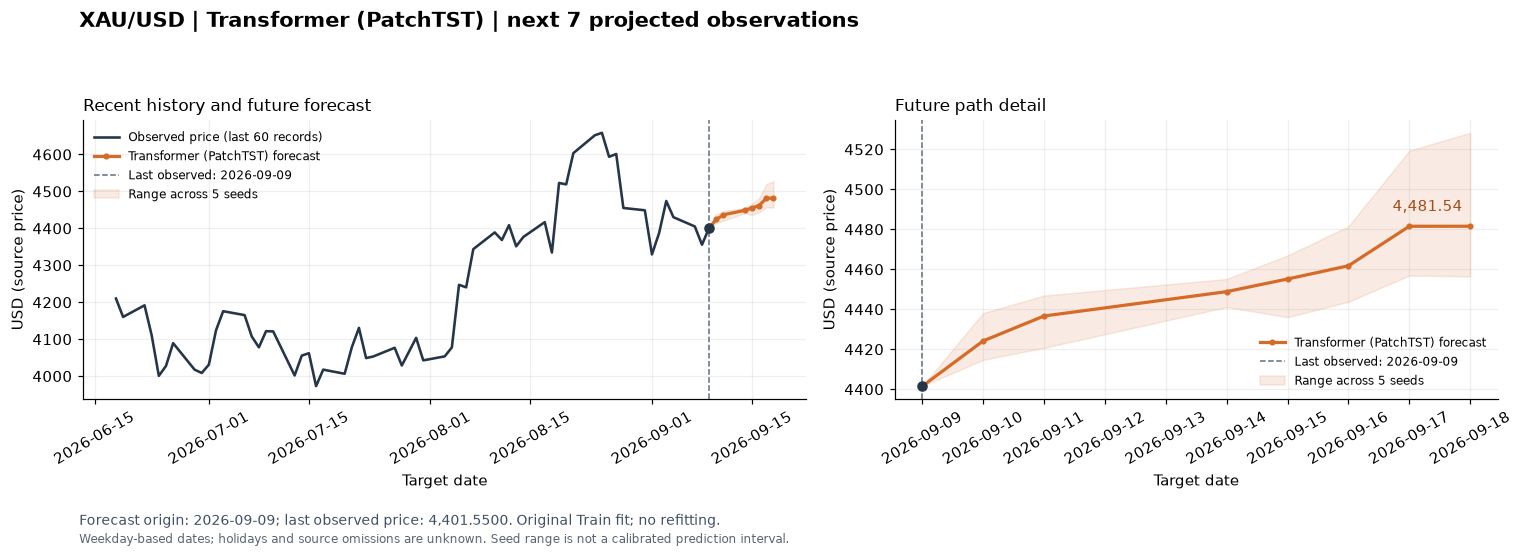

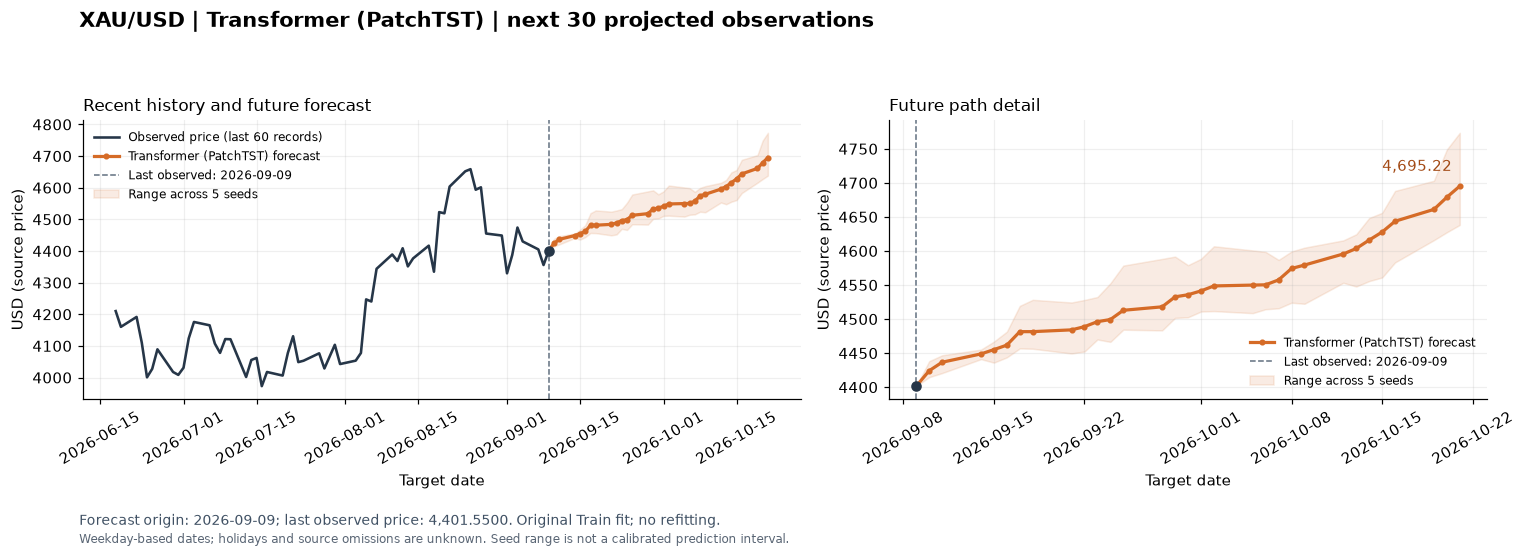

In [2]:
# Plot the already computed future path; no fitting or new inference.
FUTURE_MODEL_LABEL = 'Transformer (PatchTST)'
FUTURE_UNCERTAINTY_NOTE = 'Seed range is not a calibrated prediction interval.'
FUTURE_PLOT_LABEL = 'XAU/USD'
FUTURE_PLOT_UNIT = 'USD (source price)'
FUTURE_STEP_LABEL = 'projected observations'
FUTURE_DATE_NOTE = 'Weekday-based dates; holidays and source omissions are unknown.'

def plot_model_future_path(history, future_path, steps):
    path = future_path.sort_values('h').iloc[:steps].copy()
    origin = pd.Timestamp(history.index[-1])
    last_actual = float(history.iloc[-1])
    forecast_column = next(c for c in ['svr_fc', 'xgb_fc', 'patchtst_fc_ens', 'forecast'] if c in path)
    seed_columns = [column for column in path if column.startswith(('patchtst_fc_seed', 'forecast_seed'))]
    dates = pd.DatetimeIndex(pd.to_datetime(path['target_date']))
    values = path[forecast_column].to_numpy(dtype=float)
    assert len(path) == steps and path['h'].tolist() == list(range(1, steps + 1))
    assert dates.is_unique and dates.is_monotonic_increasing and (dates > origin).all()
    assert (pd.to_datetime(path['origin_date']) == origin).all()
    assert np.isfinite(values).all() and (values > 0).all()
    np.testing.assert_allclose(path['price_origin'], last_actual, rtol=1e-12)

    joined_dates = pd.DatetimeIndex([origin, *dates])
    joined_forecast = np.r_[last_actual, values]
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [1.2, 1]})
    recent = history.iloc[-60:]
    axes[0].plot(recent.index, recent, color='#263648', linewidth=1.7, label='Observed price (last 60 records)')
    for ax in axes:
        ax.plot(joined_dates, joined_forecast, color='#d56b27', linewidth=2.1,
                marker='o', markersize=3, label=f'{FUTURE_MODEL_LABEL} forecast')
        ax.axvline(origin, color='#627080', linestyle='--', linewidth=1,
                   label=f'Last observed: {origin:%Y-%m-%d}')
        ax.scatter([origin], [last_actual], color='#263648', s=35, zorder=4)
        if seed_columns:
            seed_values = path[seed_columns].to_numpy(dtype=float)
            assert np.isfinite(seed_values).all() and (seed_values > 0).all()
            low = np.r_[last_actual, seed_values.min(axis=1)]
            high = np.r_[last_actual, seed_values.max(axis=1)]
            ax.fill_between(joined_dates, low, high, color='#d56b27', alpha=.13,
                            label=f'Range across {len(seed_columns)} seeds')
        if {'xgb_lo95', 'xgb_hi95'}.issubset(path.columns):
            interval = path[['xgb_lo95', 'xgb_hi95']].to_numpy(dtype=float)
            assert np.isfinite(interval).all() and (interval > 0).all()
            assert (interval[:, 0] <= interval[:, 1]).all()
            ax.fill_between(joined_dates, np.r_[last_actual, interval[:, 0]],
                            np.r_[last_actual, interval[:, 1]], color='#d56b27', alpha=.13,
                            label='Nominal 95% quantile prediction interval')
        ax.set(ylabel=FUTURE_PLOT_UNIT, xlabel='Target date')
        ax.grid(alpha=.2)
        ax.spines[['top', 'right']].set_visible(False)
        ax.tick_params(axis='x', labelrotation=30)
    axes[0].set_title('Recent history and future forecast', loc='left', fontsize=11)
    axes[1].set_title('Future path detail', loc='left', fontsize=11)
    endpoint_label = f'{values[-1]:,.6f}' if FUTURE_PLOT_LABEL == 'USD/EUR' else f'{values[-1]:,.2f}'
    axes[1].annotate(endpoint_label, xy=(dates[-1], values[-1]),
                     xytext=(-5, 10), textcoords='offset points', ha='right', color='#a34a15')
    axes[0].legend(loc='best', fontsize=8, frameon=False)
    axes[1].legend(loc='best', fontsize=8, frameon=False)
    fig.suptitle(f'{FUTURE_PLOT_LABEL} | {FUTURE_MODEL_LABEL} | next {steps} {FUTURE_STEP_LABEL}',
                 fontsize=14, fontweight='bold', x=.055, ha='left')
    fig.text(.055, .045, f'Forecast origin: {origin:%Y-%m-%d}; last observed price: {last_actual:,.4f}. '
             'Original Train fit; no refitting.', fontsize=9, color='#405164')
    fig.text(.055, .012, FUTURE_DATE_NOTE + ' ' + FUTURE_UNCERTAINTY_NOTE,
             fontsize=8, color='#596574')
    fig.tight_layout(rect=(0, .08, 1, .92))
    return fig

for future_steps in [7, 30]:
    future_fig = plot_model_future_path(df['Price'], future_forecast_daily, future_steps)
    plt.show()
    plt.close(future_fig)


## 12. Process checks and RMSE/MAPE
Check all alignment, counts, unique origins, finite outputs and valid inverse transforms before scoring. Export offending rows and stop on failure; do not clip. Report RMSE in original units, MAPE in percent and sample size separately by horizon. Zero actuals make group MAPE undefined rather than changing the denominator.

In [16]:
def validate_forecasts(frame,label):
    cols=[c for c in ['actual','forecast','price_origin','lower95','upper95'] if c in frame]
    good=np.isfinite(frame[cols]).all(axis=1) & frame.forecast.gt(0)
    if 'actual' in frame: good &= frame.actual.gt(0)
    if 'lower95' in frame: good &= frame.lower95.gt(0) & frame.lower95.le(frame.forecast) & frame.forecast.le(frame.upper95)
    save_table(frame.loc[~good],f'{label}_offending_rows.csv')
    check(f'{label}: finite and valid log inversion',bool(good.all()),'No clipping or post-Test parameter revision.')
    check(f'{label}: unique origin/horizon',not frame.duplicated(['origin_date','h']).any())
    if 'target_index' in frame:
        check(f'{label}: target alignment',bool((frame.target_index==frame.origin_index+frame.h).all()) and
            (frame.target_index>=n_train).all() and (frame.target_index<n).all() and
            np.array_equal(pd.to_datetime(frame.target_date).to_numpy(),df.index[frame.target_index].to_numpy()) and
            np.array_equal(pd.to_datetime(frame.origin_date).to_numpy(),df.index[frame.origin_index].to_numpy()) and
            np.array_equal(frame.actual.to_numpy(),prices[frame.target_index]),
            'Dates come from actual observed row positions, never calendar-day addition.')
        for h in HORIZONS:
            check(f'{label}: h={h} count',int(frame.h.eq(h).sum())==n_test-h+1,statistic=int(frame.h.eq(h).sum()))
    else:
        check(f'{label}: future-only dates',bool((frame.target_date>df.index[-1]).all()) and len(frame)==len(HORIZONS))
validate_forecasts(forecasts,'test')
validate_forecasts(future_forecasts,'future')
def score(frame):
    rows=[]
    for h,g in frame.groupby('h',sort=True):
        actual=g.actual.to_numpy(); forecast=g.forecast.to_numpy()
        zero=int((actual==0).sum())
        rows.append(dict(h=h,n=len(g),first_target_date=g.target_date.min(),last_target_date=g.target_date.max(),
            RMSE=np.sqrt(np.mean((actual-forecast)**2)),MAPE=np.nan if zero else 100*np.mean(np.abs((actual-forecast)/actual)),
            zero_actuals=zero,RMSE_unit=UNIT,MAPE_unit='%'))
    return pd.DataFrame(rows)
evaluation=score(forecasts)
save_table(evaluation,'metrics_by_horizon.csv')
display(Markdown('### Historical Test RMSE and MAPE (after forecast tables)'))
display(evaluation)
seed_metrics=None
if seed_forecasts:
    frames=[]
    for seed,frame in seed_forecasts.items():
        validate_forecasts(frame,f'seed{seed}_test')
        save_table(frame,f'seed{seed}_test_forecasts.csv')
        metrics=score(frame); metrics.insert(0,'seed',seed); frames.append(metrics)
    seed_metrics=pd.concat(frames,ignore_index=True)
    save_table(seed_metrics,'seed_metrics.csv')
    seed_summary=seed_metrics.groupby('h').agg(RMSE_mean=('RMSE','mean'),RMSE_SD=('RMSE','std'),MAPE_mean=('MAPE','mean'),MAPE_SD=('MAPE','std')).reset_index()
    save_table(seed_summary,'seed_metric_summary.csv')
    display(Markdown('Individual seeds and sample SD (ddof=1); separate from return-space ensemble metrics'))
    display(seed_metrics); display(seed_summary)

### Historical Test RMSE and MAPE (after forecast tables)

,h,n,first_target_date,last_target_date,RMSE,MAPE,zero_actuals,RMSE_unit,MAPE_unit
0,1,267,2025-09-02,2026-09-09,81.885179,1.266721,0,USD (source price),%
1,3,265,2025-09-04,2026-09-09,141.065366,2.174214,0,USD (source price),%
2,5,263,2025-09-08,2026-09-09,184.321646,3.046832,0,USD (source price),%
3,7,261,2025-09-10,2026-09-09,221.492502,3.748967,0,USD (source price),%
4,14,254,2025-09-19,2026-09-09,324.701182,5.272806,0,USD (source price),%
5,21,247,2025-09-30,2026-09-09,415.811616,7.097272,0,USD (source price),%
6,30,238,2025-10-13,2026-09-09,541.027054,9.349220,0,USD (source price),%


Individual seeds and sample SD (ddof=1); separate from return-space ensemble metrics

,seed,h,n,first_target_date,last_target_date,RMSE,MAPE,zero_actuals,RMSE_unit,MAPE_unit
0,0,1,267,2025-09-02,2026-09-09,84.017180,1.310986,0,USD (source price),%
1,0,3,265,2025-09-04,2026-09-09,144.331451,2.220674,0,USD (source price),%
2,0,5,263,2025-09-08,2026-09-09,189.587165,3.136510,0,USD (source price),%
3,0,7,261,2025-09-10,2026-09-09,230.881024,3.852892,0,USD (source price),%
4,0,14,254,2025-09-19,2026-09-09,333.114796,5.363704,0,USD (source price),%
5,0,21,247,2025-09-30,2026-09-09,425.904464,7.215695,0,USD (source price),%
6,0,30,238,2025-10-13,2026-09-09,552.666851,9.475692,0,USD (source price),%
7,1,1,267,2025-09-02,2026-09-09,81.965673,1.271519,0,USD (source price),%
8,1,3,265,2025-09-04,2026-09-09,141.273839,2.184290,0,USD (source price),%
9,1,5,263,2025-09-08,2026-09-09,185.357853,3.076581,0,USD (source price),%


,h,RMSE_mean,RMSE_SD,MAPE_mean,MAPE_SD
0,1,82.625350,0.828308,1.281459,0.017158
1,3,142.743803,1.492145,2.219382,0.033436
2,5,186.534327,1.773620,3.089024,0.048403
3,7,224.454839,3.685559,3.793174,0.044995
4,14,328.650348,4.996383,5.351351,0.036733
5,21,420.572378,4.188289,7.178911,0.057575
6,30,546.695760,5.224454,9.426963,0.049033


## 13. Forecast plots and reporting-only Test residual diagnostics
Higher horizons can have overlapping errors and different target counts. Descriptive diagnostic p-values and Train/Test scale comparisons do not trigger model changes.

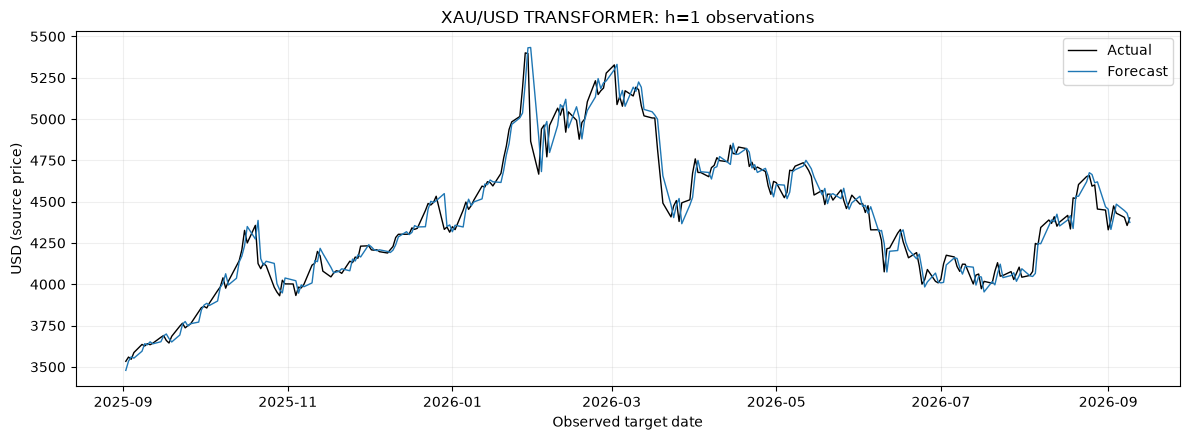

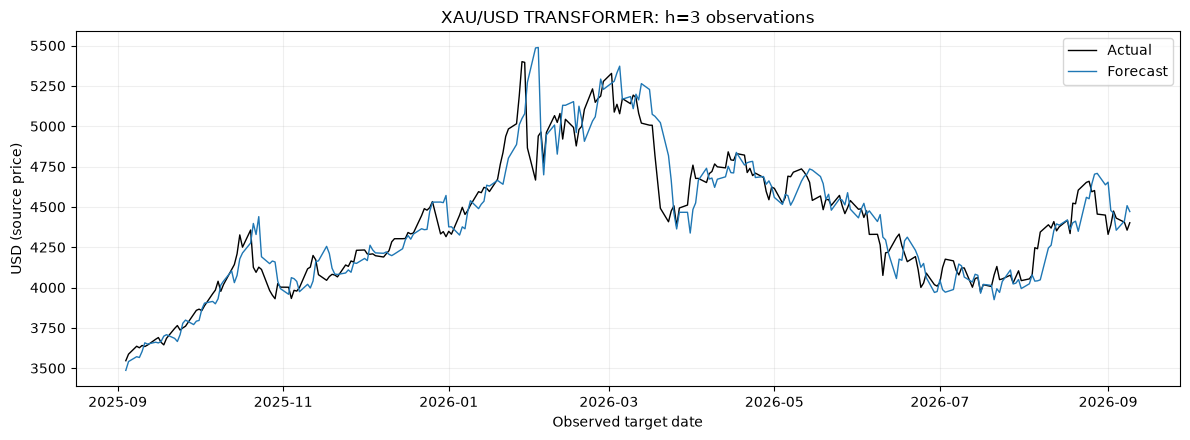

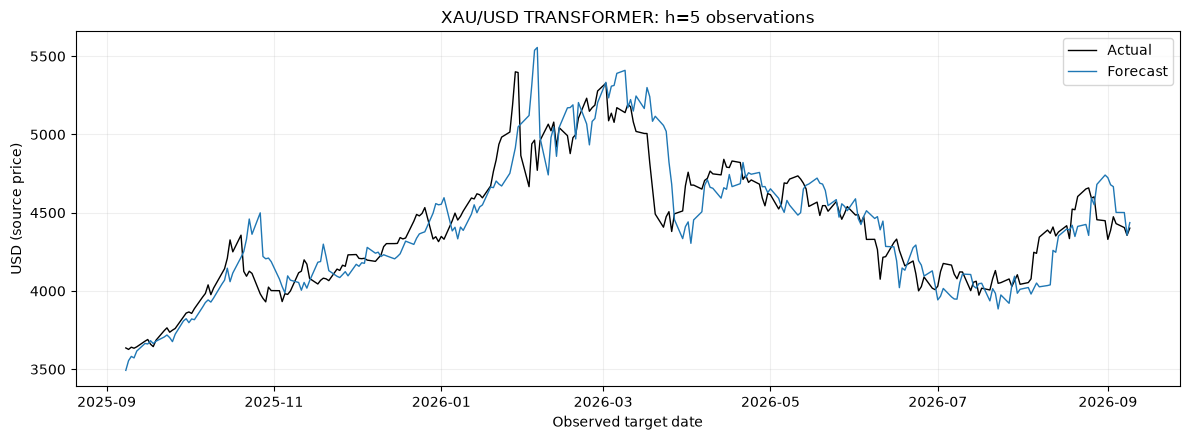

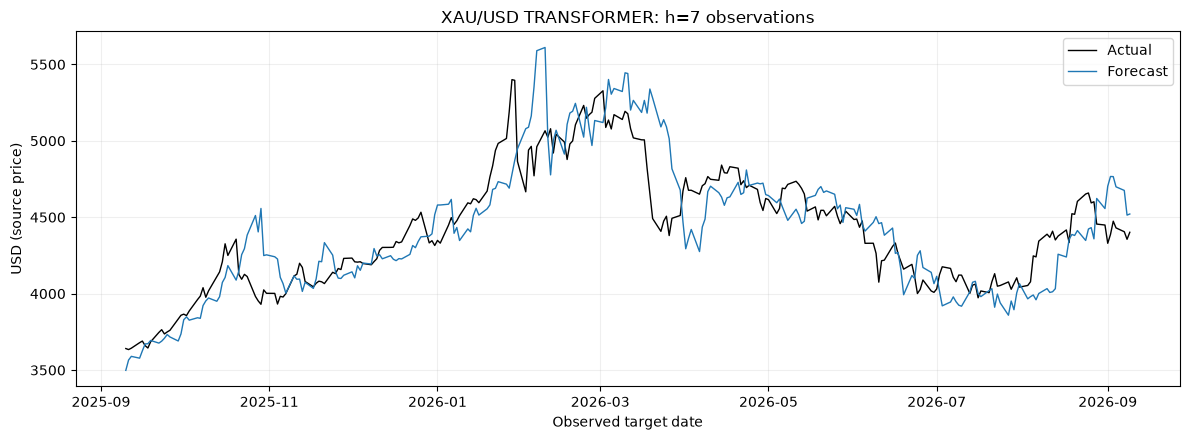

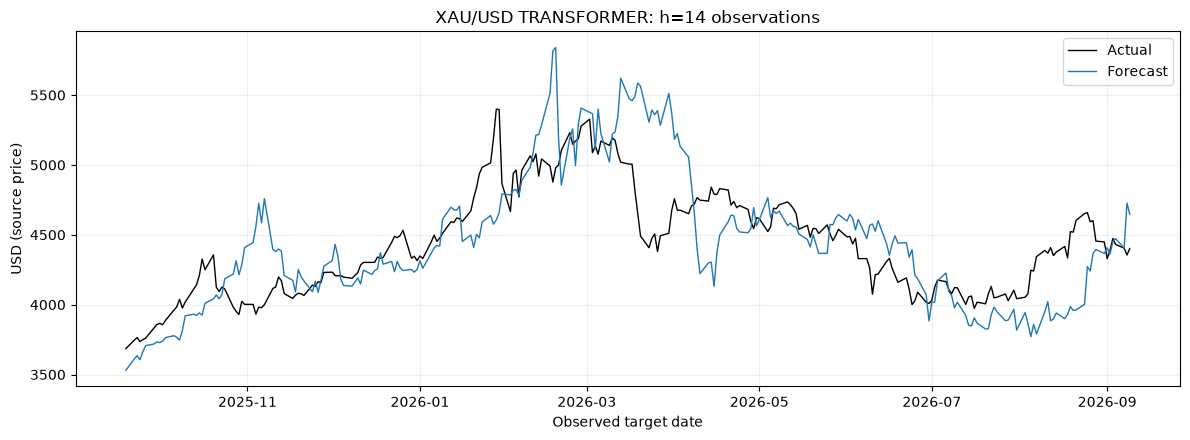

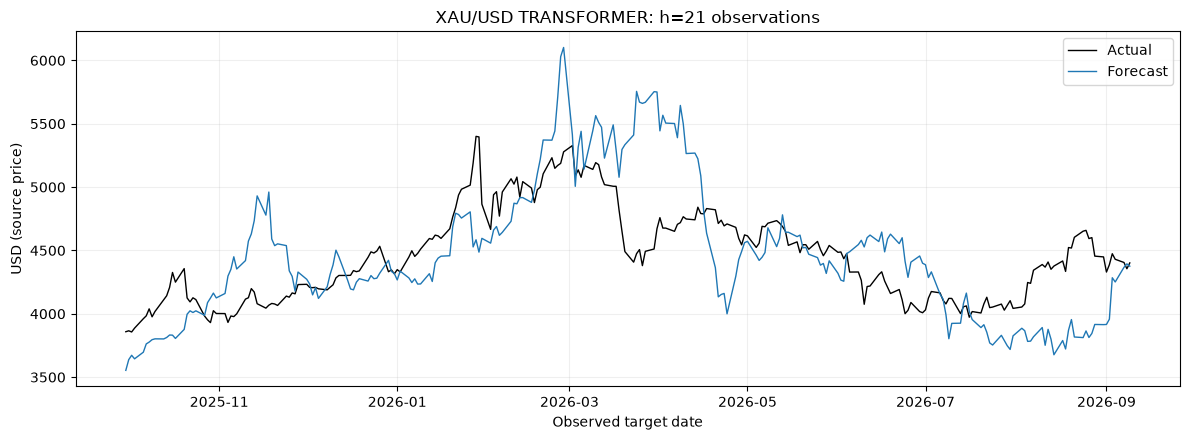

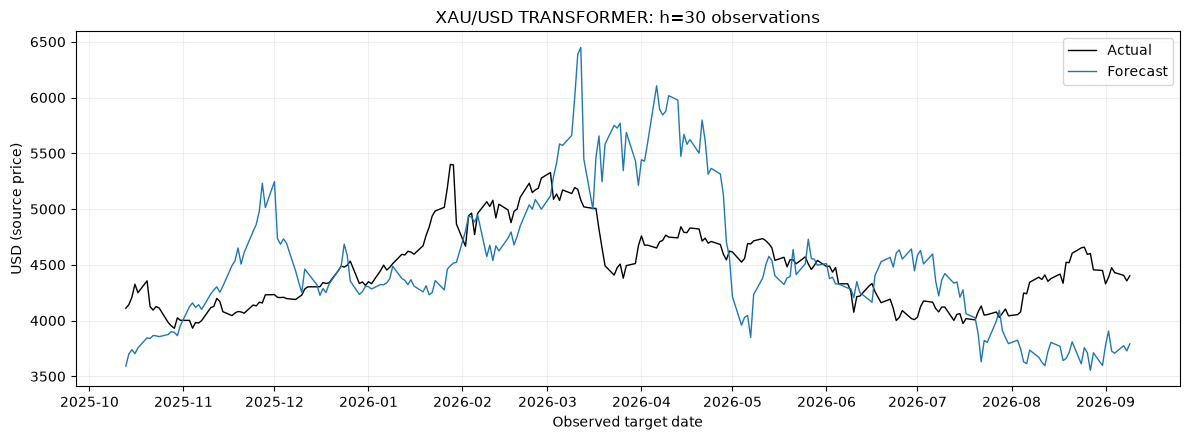

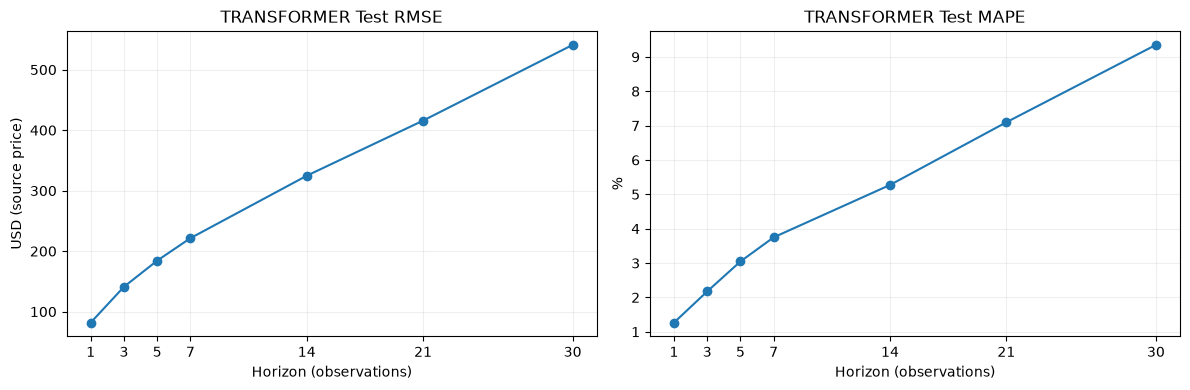

C:\Users\User\anaconda3\envs\vs_nine_tf\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,sample,check,statistic,p_value,status,interpretation
0,Test cumulative log-return errors h=1; reporti...,Ljung-Box lag 10,12.246885,2.688732e-01,REPORTED,No rejection of residual independence; model_d...
1,Test cumulative log-return errors h=1; reporti...,Ljung-Box lag 20,24.924584,2.043316e-01,REPORTED,No rejection of residual independence; model_d...
2,Test cumulative log-return errors h=1; reporti...,Ljung-Box lag 30,30.423140,4.441434e-01,REPORTED,No rejection of residual independence; model_d...
3,Test cumulative log-return errors h=1; reporti...,Residual mean t-test,-0.588153,5.569288e-01,REPORTED,"Mean=-0.00063894164; descriptive, dependent er..."
4,Test cumulative log-return errors h=1; reporti...,ARCH LM,18.392576,4.869165e-02,REPORTED,Conditional variance evidence; no retuning
5,Test cumulative log-return errors h=1; reporti...,Jarque-Bera,410.129546,8.739782e-90,REPORTED,Normality diagnostic; skew=-1.1446; kurtosis=8...


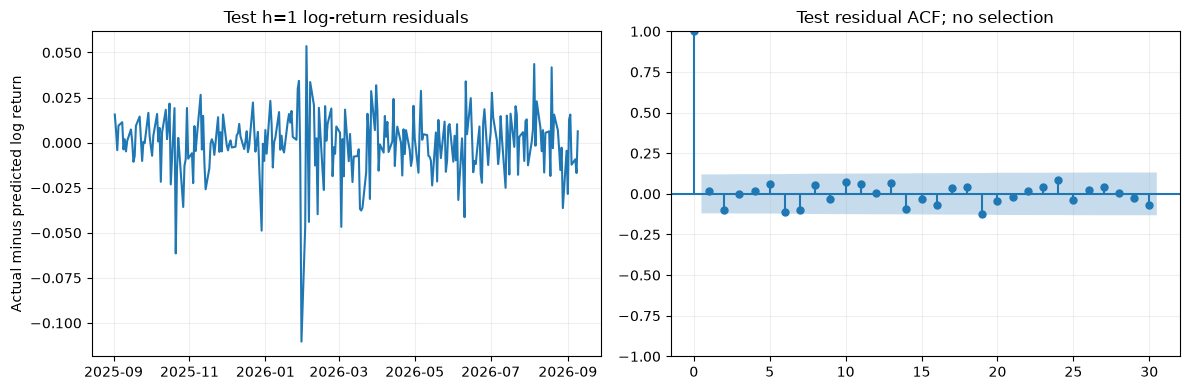

,sample,n,mean,SD,status
0,Train,1065,0.000619,0.009301,REPORTED
1,Test,267,0.000884,0.017648,REPORTED


In [17]:
for h in HORIZONS:
    g=forecasts.loc[forecasts.h.eq(h)].sort_values('target_date')
    fig,ax=plt.subplots()
    ax.plot(g.target_date,g.actual,label='Actual',color='black',linewidth=1)
    ax.plot(g.target_date,g.forecast,label='Forecast',linewidth=1)
    if 'lower95' in g: ax.fill_between(g.target_date,g.lower95,g.upper95,alpha=.2,label='Model-based 95% interval')
    ax.set(title=f'{ASSET_NAME} {MODEL}: h={h} observations',xlabel='Observed target date',ylabel=UNIT)
    ax.legend(); save_figure(fig,f'test_forecast_h{h}.png')
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,metric,unit in zip(axes,['RMSE','MAPE'],[UNIT,'%']):
    ax.plot(evaluation.h,evaluation[metric],marker='o')
    ax.set(title=f'{MODEL} Test {metric}',xlabel='Horizon (observations)',ylabel=unit,xticks=HORIZONS)
save_figure(fig,'metrics_by_horizon.png')
hdiag=HORIZONS[0]
g=forecasts.loc[forecasts.h.eq(hdiag)].sort_values('origin_date')
errors=np.log(g.actual/g.price_origin)-g.predicted_log_return
test_diagnostics=residual_report(errors,f'Test cumulative log-return errors h={hdiag}; reporting only')
save_table(test_diagnostics,'test_residual_diagnostics.csv'); display(test_diagnostics)
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(g.target_date,errors); axes[0].set(title=f'Test h={hdiag} log-return residuals',ylabel='Actual minus predicted log return')
plot_acf(errors,lags=min(30,len(errors)//4),ax=axes[1]); axes[1].set_title('Test residual ACF; no selection')
save_figure(fig,'test_residual_diagnostics.png')
scale_comparison=pd.DataFrame([dict(sample='Train',n=n_train-1,mean=np.mean(returns[1:n_train]),SD=np.std(returns[1:n_train],ddof=1),status='REPORTED'),
    dict(sample='Test',n=n_test,mean=np.mean(returns[n_train:]),SD=np.std(returns[n_train:],ddof=1),status='REPORTED')])
save_table(scale_comparison,'return_scale_comparison.csv'); display(scale_comparison)

## 14. Summary generated from this execution
Rerunning regenerates this report from current results; there is no copied saved-result markdown.

In [18]:
lines=[f'# {ASSET_NAME} - {MODEL}: results from this execution','',
    f'Source: `{DATA_PATH.name}`; target: {TARGET_COL}; units: {UNIT}.',ASSET_NOTE,'',
    f'Raw chronological Train/Test: {n_train}/{n_test}; no validation.',
    f'Train: {df.index[0].date()} to {df.index[T].date()}; Test: {df.index[n_train].date()} to {df.index[-1].date()}.',
    f'Horizons: {HORIZONS} observations. Lookback: {LOOKBACK} observed returns for window models.',CALENDAR_NOTE,
    f'Source calendar audit: {len(missing_dates)} dates absent relative to the declared weekday pattern; maximum gap {int(gaps.calendar_days.max())} calendar days.',
    'Missing source dates are disclosed, not filled. Observation time therefore need not equal elapsed calendar time.',
    'Rolling origins begin at the final Train observation. Each forecast uses only history through its own origin; fitted parameters remain fixed.','',
    '## Model development']
if MODEL=='ARIMA':
    lines += [f'Selected {selected.model}; Train AIC={selected.AIC:.6f}; BIC={selected.BIC:.6f}.',
        'Differencing is the smallest Train ADF/KPSS-supported order. Selection uses AIC among converged fits with valid roots. Residual tests are reported without retuning.',
        'Exponentiated log forecasts are conditional medians, not bias-corrected arithmetic means. The 95% intervals are model-based; ARCH/non-normality and calendar irregularity limit interpretation.']
    if int(selected.p)==0 and d==1 and int(selected.q)==0 and selected.trend=='n':
        lines.append('ARIMA(0,1,0) without drift gives the latest observed price as the point forecast; uncertainty increases with horizon.')
elif MODEL=='SVR':
    lines += ['Direct cumulative-log-return RBF models use the fixed Train-only C/epsilon heuristic and Train input/target scalers. No hyperparameter cross-validation.']
elif MODEL=='XGBOOST':
    lines += ['Direct cumulative-log-return models use a fixed predeclared configuration. Learning curves are fitting data only. Raw gain is neither causal importance nor proof of future usefulness.']
else:
    lines += [f'MIMO predicts the next {MAX_H} individual observed-step log returns; prices compound the predicted path only.',
        f'All predefined seeds {SEEDS} are included equally; {EPOCHS} fixed epochs each. Average inverse-scaled returns before compounding.',
        'Ensemble metrics are not the mean seed metrics. Seed metric SD uses ddof=1 and is not a prediction interval.']
lines += ['', '## Historical Test metrics',markdown_table(evaluation),'',
    'Horizon groups have different counts and target dates; longer-horizon forecast errors overlap. These values do not establish a monotonic relationship with horizon.',
    'MAPE is an error percentage, not accuracy. Actual targets are checked for zeros; any zero would make the full-group MAPE undefined.',
    '', '## Future forecasts (no actuals or metrics)',markdown_table(future_forecasts),'',
    'Future dates are projections from a declared source-weekday pattern, not confirmed exchange sessions. Holidays or missing future records can shift them.',
    '', '## Checks and limitations',
    f'Process checks: {sum(row["status"]=="PASS" for row in process_rows)} passed; {sum(row["status"]=="FAIL" for row in process_rows)} failed.',
    'Train/Test diagnostics with no predeclared acceptance gate are REPORTED. Passing diagnostics does not establish forecast accuracy.',
    'No separate validation estimate or validation gap exists. Train fitting loss is optimistic; fixed budgets do not establish absence of overfitting.',
    'Test findings did not change parameters, epochs, transformations, seeds, or model selection.',
    'These univariate models do not observe news, monetary policy, interest rates, inflation, or unexpected market events.',
    f'All rows, figures, summaries and fitted artifacts are under OUTPUT/{MODEL}_{ASSET}/.',
    f'Tested Python executable: {sys.executable}.']
lines += ['', '**Daily future forecasts**', 'Tables for 7 and 30 future steps are shown before metrics; dates follow the existing asset calendar convention.']
summary='\n\n'.join(lines)
(SUMMARY_DIR/'execution_summary.md').write_text(summary,encoding='utf-8')
display(Markdown(summary))
write_json(SUMMARY_DIR/'execution_audit.json',dict(completed=True,asset=ASSET,model=MODEL,
    n=n,n_train=n_train,n_test=n_test,horizons=HORIZONS,counts={int(h):int(c) for h,c in forecasts.groupby('h').size().items()},
    train_end=str(df.index[T].date()),test_start=str(df.index[n_train].date()),last_observation=str(df.index[-1].date()),
    parameters_frozen=model_fingerprint()==frozen_state,process_checks=process_rows,
    source_sha256=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),seed_count=len(seed_forecasts),python_executable=sys.executable))

# XAU/USD - TRANSFORMER: results from this execution



Source: `XAU_USD Historical Data.csv`; target: Price; units: USD (source price).

The filename identifies XAU/USD. The CSV does not identify fixing, venue, close time, timezone, or adjustments. Gold is conventionally quoted per troy ounce; this file has no physical-unit metadata, so metrics retain source USD price units.



Raw chronological Train/Test: 1066/267; no validation.

Train: 2021-07-26 to 2025-09-01; Test: 2025-09-02 to 2026-09-09.

Horizons: [1, 3, 5, 7, 14, 21, 30] observations. Lookback: 40 observed returns for window models.

Observation-index modeling; source dates retained without filling gaps. Future dates use the declared weekday pattern only; holidays, omitted records and source-session conventions remain unknown.

Source calendar audit: 5 dates absent relative to the declared weekday pattern; maximum gap 4 calendar days.

Missing source dates are disclosed, not filled. Observation time therefore need not equal elapsed calendar time.

Rolling origins begin at the final Train observation. Each forecast uses only history through its own origin; fitted parameters remain fixed.



## Model development

MIMO predicts the next 30 individual observed-step log returns; prices compound the predicted path only.

All predefined seeds [0, 1, 2, 3, 4] are included equally; 100 fixed epochs each. Average inverse-scaled returns before compounding.

Ensemble metrics are not the mean seed metrics. Seed metric SD uses ddof=1 and is not a prediction interval.



## Historical Test metrics

| h | n | first_target_date | last_target_date | RMSE | MAPE | zero_actuals | RMSE_unit | MAPE_unit |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 267 | 2025-09-02 00:00:00 | 2026-09-09 00:00:00 | 81.885179 | 1.266721 | 0 | USD (source price) | % |
| 3 | 265 | 2025-09-04 00:00:00 | 2026-09-09 00:00:00 | 141.065366 | 2.174214 | 0 | USD (source price) | % |
| 5 | 263 | 2025-09-08 00:00:00 | 2026-09-09 00:00:00 | 184.321646 | 3.046832 | 0 | USD (source price) | % |
| 7 | 261 | 2025-09-10 00:00:00 | 2026-09-09 00:00:00 | 221.492502 | 3.748967 | 0 | USD (source price) | % |
| 14 | 254 | 2025-09-19 00:00:00 | 2026-09-09 00:00:00 | 324.701182 | 5.272806 | 0 | USD (source price) | % |
| 21 | 247 | 2025-09-30 00:00:00 | 2026-09-09 00:00:00 | 415.811616 | 7.097272 | 0 | USD (source price) | % |
| 30 | 238 | 2025-10-13 00:00:00 | 2026-09-09 00:00:00 | 541.027054 | 9.349220 | 0 | USD (source price) | % |



Horizon groups have different counts and target dates; longer-horizon forecast errors overlap. These values do not establish a monotonic relationship with horizon.

MAPE is an error percentage, not accuracy. Actual targets are checked for zeros; any zero would make the full-group MAPE undefined.



## Future forecasts (no actuals or metrics)

| h | origin_date | target_date | target_date_status | price_origin | forecast |
| --- | --- | --- | --- | --- | --- |
| 1 | 2026-09-09 00:00:00 | 2026-09-10 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 4401.550000 | 4424.169536 |
| 3 | 2026-09-09 00:00:00 | 2026-09-14 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 4401.550000 | 4448.821257 |
| 5 | 2026-09-09 00:00:00 | 2026-09-16 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 4401.550000 | 4461.767844 |
| 7 | 2026-09-09 00:00:00 | 2026-09-18 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 4401.550000 | 4481.542426 |
| 14 | 2026-09-09 00:00:00 | 2026-09-29 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 4401.550000 | 4532.659250 |
| 21 | 2026-09-09 00:00:00 | 2026-10-08 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 4401.550000 | 4574.281001 |
| 30 | 2026-09-09 00:00:00 | 2026-10-21 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 4401.550000 | 4695.219881 |



Future dates are projections from a declared source-weekday pattern, not confirmed exchange sessions. Holidays or missing future records can shift them.



## Checks and limitations

Process checks: 75 passed; 0 failed.

Train/Test diagnostics with no predeclared acceptance gate are REPORTED. Passing diagnostics does not establish forecast accuracy.

No separate validation estimate or validation gap exists. Train fitting loss is optimistic; fixed budgets do not establish absence of overfitting.

Test findings did not change parameters, epochs, transformations, seeds, or model selection.

These univariate models do not observe news, monetary policy, interest rates, inflation, or unexpected market events.

All rows, figures, summaries and fitted artifacts are under OUTPUT/TRANSFORMER_XAU/.

Tested Python executable: C:\Users\User\anaconda3\envs\vs_nine_tf\python.exe.



**Daily future forecasts**

Tables for 7 and 30 future steps are shown before metrics; dates follow the existing asset calendar convention.

## Implementation reference
- Local reference: `../BTC_TEST/TRANSFORMER_BTC.ipynb` (read only; not rerun or modified).
- User protocol: `C:/Users/User/.codex/skills/time-series-forecasting/SKILL.md` and its asset-adaptation/model references.
- These notebooks adapt the local implementation; they do not claim replication of a separately tuned external study.